# 🎬 Movie Recommendation System

##  Import Required Libraries
This section imports all important libraries required for the project.

Different libraries perform different tasks such as:

#### Purpose
Libraries are used for:
- Data handling
- Visualization
- NLP
- Machine Learning
- Sentiment Analysis

---
#### Why These Libraries Used?

| Library | Purpose |
|---|---|
| `numpy` | Numerical operations |
| `pandas` | Data handling |
| `matplotlib` | Data visualization |
| `seaborn` | Advanced visualization |
| `re` | Text cleaning |
| `nltk` | NLP preprocessing |
| `TextBlob` | Sentiment analysis |
| `TfidfVectorizer` | Convert text into vectors |
| `linear_kernel` | Similarity calculation |
| `psutil` | RAM monitoring |

---

In [1]:
import psutil
print(f"{psutil.virtual_memory().available/1e9:.2f} GB available")
print(f"{psutil.virtual_memory().percent}%")

7.96 GB available
53.7%


In [2]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer
from textblob import TextBlob
from sklearn.metrics.pairwise import linear_kernel
import warnings

warnings.filterwarnings('ignore')
print("All libraries imported successfully!")


All libraries imported successfully!


In [3]:
import gc
gc.collect()

26

### Download NLTK Resources

#### Explanation

NLTK resources are downloaded because NLP functions require additional datasets.

These resources help in:
- Splitting words
- Removing stopwords
- Lemmatization

---

#### Resources Used

| Resource | Purpose |
|---|---|
| `punkt_tab` | Tokenization |
| `stopwords` | Remove common words |
| `wordnet` | Lemmatization |
| `omw-1.4` | Extra language support |

---

In [4]:
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')  
nltk.download('omw-1.4')

[nltk_data] Downloading package punkt_tab to
[nltk_data]     /Users/vedikabengani/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/vedikabengani/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     /Users/vedikabengani/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     /Users/vedikabengani/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

### Load Dataset

#### Explanation

Datasets are loaded into pandas DataFrames.

Two datasets are used:

| Dataset | Contains |
|---|---|
| Movies Dataset | Movie details |
| Reviews Dataset | User/Critic reviews |

---

#### Why Important?

Datasets are the foundation of the recommendation system.

Without data:
- No training
- No similarity
- No recommendation

---

In [5]:
movies=pd.read_csv("../datasets/rotten_tomatoes_movies.csv")
review=pd.read_csv("../datasets/rotten_tomatoes_movie_reviews.csv")
# See sample of data first 5 rows
movies.head()

,id,title,audienceScore,tomatoMeter,rating,ratingContents,releaseDateTheaters,releaseDateStreaming,runtimeMinutes,genre,originalLanguage,director,writer,boxOffice,distributor,soundMix
0,space-zombie-bingo,Space Zombie Bingo!,50.0,NaN,NaN,NaN,NaN,2018-08-25,75.0,"Comedy, Horror, Sci-fi",English,George Ormrod,"George Ormrod,John Sabotta",NaN,NaN,NaN
1,the_green_grass,The Green Grass,NaN,NaN,NaN,NaN,NaN,2020-02-11,114.0,Drama,English,Tiffany Edwards,Tiffany Edwards,NaN,NaN,NaN
2,love_lies,"Love, Lies",43.0,NaN,NaN,NaN,NaN,NaN,120.0,Drama,Korean,"Park Heung-Sik,Heung-Sik Park","Ha Young-Joon,Jeon Yun-su,Song Hye-jin",NaN,NaN,NaN
3,the_sore_losers_1997,Sore Losers,60.0,NaN,NaN,NaN,NaN,2020-10-23,90.0,"Action, Mystery & thriller",English,John Michael McCarthy,John Michael McCarthy,NaN,NaN,NaN
4,dinosaur_island_2002,Dinosaur Island,70.0,NaN,NaN,NaN,NaN,2017-03-27,80.0,"Fantasy, Adventure, Animation",English,Will Meugniot,John Loy,NaN,NaN,NaN


In [6]:
movies.tail()

,id,title,audienceScore,tomatoMeter,rating,ratingContents,releaseDateTheaters,releaseDateStreaming,runtimeMinutes,genre,originalLanguage,director,writer,boxOffice,distributor,soundMix
143253,nadia_the_secret_of_blue_water_the_motion_pict...,Nadia: The Secret of Blue Water: The Motion Pi...,14.0,NaN,NaN,NaN,2002-08-27,NaN,90.0,"Action, Adventure, Anime",Japanese,Sho Aono,Kaoru Umeno,NaN,ADV Films,NaN
143254,everyone_i_knew_and_loved,Everyone I Knew and Loved,NaN,NaN,NaN,NaN,NaN,NaN,99.0,Drama,English,Andrew Behringer,Erika Heidewald,NaN,NaN,NaN
143255,the-human-body,The Human Body,71.0,89.0,NaN,NaN,NaN,NaN,43.0,Documentary,English,Peter Georgi,Richard Dale,NaN,NaN,NaN
143256,flying_fists,Flying Fists,NaN,NaN,NaN,NaN,NaN,2006-11-21,63.0,Drama,English,Robert F. Hill,"Robert F. Hill,Basil Dickey",NaN,NaN,NaN
143257,awakening-2005,Awakening,NaN,NaN,NaN,NaN,NaN,NaN,90.0,Horror,English,David J. Francis,"David J. Francis,Mike Masters",NaN,NaN,NaN


In [7]:
review.head()

,id,reviewId,creationDate,criticName,isTopCritic,originalScore,reviewState,publicatioName,reviewText,scoreSentiment,reviewUrl
0,beavers,1145982,2003-05-23,Ivan M. Lincoln,False,3.5/4,fresh,Deseret News (Salt Lake City),Timed to be just long enough for most youngste...,POSITIVE,http://www.deseretnews.com/article/700003233/B...
1,blood_mask,1636744,2007-06-02,The Foywonder,False,1/5,rotten,Dread Central,It doesn't matter if a movie costs 300 million...,NEGATIVE,http://www.dreadcentral.com/index.php?name=Rev...
2,city_hunter_shinjuku_private_eyes,2590987,2019-05-28,Reuben Baron,False,NaN,fresh,CBR,The choreography is so precise and lifelike at...,POSITIVE,https://www.cbr.com/city-hunter-shinjuku-priva...
3,city_hunter_shinjuku_private_eyes,2558908,2019-02-14,Matt Schley,False,2.5/5,rotten,Japan Times,The film's out-of-touch attempts at humor may ...,NEGATIVE,https://www.japantimes.co.jp/culture/2019/02/0...
4,dangerous_men_2015,2504681,2018-08-29,Pat Padua,False,NaN,fresh,DCist,Its clumsy determination is endearing and some...,POSITIVE,http://dcist.com/2015/11/out_of_frame_dangerou...


In [8]:
review.tail()

,id,reviewId,creationDate,criticName,isTopCritic,originalScore,reviewState,publicatioName,reviewText,scoreSentiment,reviewUrl
1444958,thor_love_and_thunder,102706151,2022-07-05,Christie Cronan,False,7/10,fresh,Raising Whasians,Solid but not totally sold&#44; Thor&#58; Ragn...,POSITIVE,https://raisingwhasians.com/thor-love-and-thun...
1444959,thor_love_and_thunder,102706150,2022-07-05,Ian Sandwell,False,4/5,fresh,Digital Spy,Thor&#58; Love and Thunder is the most enterta...,POSITIVE,https://www.digitalspy.com/movies/a40496050/th...
1444960,thor_love_and_thunder,102706149,2022-07-05,Lauren LaMagna,False,8/10,fresh,Next Best Picture,&quot;Thor&#58; Love and Thunder&quot; is a st...,POSITIVE,https://www.nextbestpicture.com/thor-love-and-...
1444961,thor_love_and_thunder,102706148,2022-07-05,Jake Cole,True,1/4,rotten,Slant Magazine,Across Taika Waititi&#8217;s film&#44; a war a...,NEGATIVE,https://www.slantmagazine.com/film/thor-love-a...
1444962,thor_love_and_thunder,102706147,2022-07-05,Roger Moore,False,2.5/4,fresh,Movie Nation,It&#8217;s the jokes that make it&#44; with th...,POSITIVE,https://rogersmovienation.com/2022/07/05/movie...


### Remove non - revlant column 
Why These Columns Removed?

| Column Name | Reason for Removal |
|---|---|
| `releaseDateTheaters` | Date movie released in theaters — not useful for similarity |
| `releaseDateStreaming` | Date movie released on streaming — not useful for similarity |
| `soundMix` | Audio format (Dolby, DTS) — not a content feature |
| `boxOffice` | Money earned — financial data, not content-related |
| `distributor` | Distribution company — weak recommendation signal |

---

## Reviews Table — Metadata Not Useful for NLP

| Column Name | Reason for Removal |
|---|---|
| `reviewUrl` | URL link to review page — just a web address |
| `creationDate` | Date review was written — not useful for similarity |
| `reviewState` | Admin/status field (`fresh`, `rotten`) — not needed |
| `isTopCritic` | Boolean flag for critic rank — not needed for content similarity |

In [9]:
movies_to_drop=[
    'releaseDateTheaters',
    'releaseDateStreaming',
    'soundMix',
    'boxOffice',
    'distributor'
]
review_to_drop=[
    'reviewUrl', 'creationDate',
    'reviewState', 'isTopCritic'
]
movies.drop(columns=movies_to_drop,inplace=True,errors='ignore')
review.drop(columns=review_to_drop,inplace=True,errors='ignore')

In [10]:
movies.columns

Index(['id', 'title', 'audienceScore', 'tomatoMeter', 'rating',
       'ratingContents', 'runtimeMinutes', 'genre', 'originalLanguage',
       'director', 'writer'],
      dtype='str')

In [11]:
review.columns

Index(['id', 'reviewId', 'criticName', 'originalScore', 'publicatioName',
       'reviewText', 'scoreSentiment'],
      dtype='str')

### Handle Missing Values

#### Explanation

Real-world datasets contain missing values.

Machine learning models cannot handle missing values properly.

So missing values are filled using:
- Mean
- Median
- Mode

---

#### Numerical Columns

| Column | Method | Reason |
|---|---|---|
| `audienceScore` | Mean | Balanced replacement |
| `tomatoMeter` | Mean | Average score |
| `runtimeMinutes` | Median | Better for outliers |

---

#### Categorical Columns

| Column | Method |
|---|---|
| `genre` | Mode |
| `originalLanguage` | Mode |
| `rating` | Mode |

---

#### Why Mean, Median, Mode?

| Method | Best Used For |
|---|---|
| Mean | Normal numerical data |
| Median | Data with outliers |
| Mode | Categorical data |

---



In [12]:
movies.info()

<class 'pandas.DataFrame'>
RangeIndex: 143258 entries, 0 to 143257
Data columns (total 11 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   id                143258 non-null  str    
 1   title             142891 non-null  str    
 2   audienceScore     73248 non-null   float64
 3   tomatoMeter       33877 non-null   float64
 4   rating            13991 non-null   str    
 5   ratingContents    13991 non-null   str    
 6   runtimeMinutes    129431 non-null  float64
 7   genre             132175 non-null  str    
 8   originalLanguage  129400 non-null  str    
 9   director          139041 non-null  str    
 10  writer            90116 non-null   str    
dtypes: float64(3), str(8)
memory usage: 24.0 MB


In [13]:
movies.isnull().sum()

id                       0
title                  367
audienceScore        70010
tomatoMeter         109381
rating              129267
ratingContents      129267
runtimeMinutes       13827
genre                11083
originalLanguage     13858
director              4217
writer               53142
dtype: int64

In [14]:
review.isnull().sum()

id                     0
reviewId               0
criticName             0
originalScore     435218
publicatioName         0
reviewText         69225
scoreSentiment         0
dtype: int64

##### Mean()

In [15]:
movies['audienceScore']=movies['audienceScore'].fillna(movies['audienceScore'].mean())
movies['tomatoMeter'] = movies['tomatoMeter'].fillna(movies['tomatoMeter'].mean())
movies['runtimeMinutes'] = movies['runtimeMinutes'].fillna(movies['runtimeMinutes'].median()
)

##### Mode()

In [16]:
##categorical data
movies['genre']=movies['genre'].fillna(movies['genre'].mode()[0])
movies['originalLanguage'] = movies['originalLanguage'].fillna(movies['originalLanguage'].mode()[0])
movies['rating'] = movies['rating'].fillna(movies['rating'].mode()[0])


### Remove Empty Rows

#### Explanation

Some rows contain empty important values such as:
- Title
- Director
- Writer
- Review text

These rows are removed because they reduce recommendation quality.

---

#### Why Important?

Without:
- Movie title → movie cannot be identified
- Review text → NLP cannot work
- Director/Writer → similarity becomes weak

---

In [17]:
print(movies.shape)
print(review.shape)

(143258, 11)
(1444963, 7)


In [18]:
##Remove rows with missing values
movies=movies[movies['title'].notnull() & (movies['title'].str.strip()!='')]
# Remove rows where director is null
movies = movies[movies['director'].notnull() & (movies['director'].str.strip() != '')]

# Remove rows where writer is null
movies = movies[movies['writer'].notnull() & (movies['writer'].str.strip() != '')]

# Remove rows where reviewText is null
review = review[review['reviewText'].notnull() & (review['reviewText'].str.strip() != '')]

# Reset movies index
movies.reset_index(drop=True, inplace=True)

# Reset reviews index
review.reset_index(drop=True, inplace=True)

In [19]:
movies.shape

(89738, 11)

In [20]:
review.shape

(1375738, 7)

In [21]:
movies.isnull().sum()

id                      0
title                   0
audienceScore           0
tomatoMeter             0
rating                  0
ratingContents      77038
runtimeMinutes          0
genre                   0
originalLanguage        0
director                0
writer                  0
dtype: int64

In [22]:
review.isnull().sum()   

id                     0
reviewId               0
criticName             0
originalScore     435047
publicatioName         0
reviewText             0
scoreSentiment         0
dtype: int64

### Merge Dataset

#### Explanation

Movie dataset and review dataset are combined together.

This creates one final dataset containing:
- Movie details
- Reviews
- Ratings
- Sentiment information

---

#### Why Merge Important?

The recommendation system needs:
- Movie metadata
- Review information

Both together improve recommendation accuracy.

---

In [23]:
data=pd.merge(movies,review,on='id', how='left')
#Keep ALL rows from the LEFT dataset== how 
#on='idn='id is the common column in both datasets
data.head()

,id,title,audienceScore,tomatoMeter,rating,ratingContents,runtimeMinutes,genre,originalLanguage,director,writer,reviewId,criticName,originalScore,publicatioName,reviewText,scoreSentiment
0,space-zombie-bingo,Space Zombie Bingo!,50.000000,65.770346,R,NaN,75.0,"Comedy, Horror, Sci-fi",English,George Ormrod,"George Ormrod,John Sabotta",NaN,NaN,NaN,NaN,NaN,NaN
1,the_green_grass,The Green Grass,55.674967,65.770346,R,NaN,114.0,Drama,English,Tiffany Edwards,Tiffany Edwards,NaN,NaN,NaN,NaN,NaN,NaN
2,love_lies,"Love, Lies",43.000000,65.770346,R,NaN,120.0,Drama,Korean,"Park Heung-Sik,Heung-Sik Park","Ha Young-Joon,Jeon Yun-su,Song Hye-jin",2739073.0,James Mudge,4/5,easternKicks.com,Though let down by its routine love triangle n...,POSITIVE
3,love_lies,"Love, Lies",43.000000,65.770346,R,NaN,120.0,Drama,Korean,"Park Heung-Sik,Heung-Sik Park","Ha Young-Joon,Jeon Yun-su,Song Hye-jin",2333658.0,Diva Velez,3.5/5,TheDivaReview.com,"While not perfect, Love, Lies is a worthy disc...",POSITIVE
4,the_sore_losers_1997,Sore Losers,60.000000,65.770346,R,NaN,90.0,"Action, Mystery & thriller",English,John Michael McCarthy,John Michael McCarthy,NaN,NaN,NaN,NaN,NaN,NaN


In [24]:
data.shape

(1299797, 17)

### Remove Duplicate Values

### Explanation

Duplicate rows mean repeated records.

Duplicates can:
- Bias the model
- Increase memory usage
- Produce incorrect recommendations

So duplicates are removed.

---

In [25]:
data.drop_duplicates(inplace=True)
# reset index
data.reset_index(drop=True, inplace=True)

In [26]:
data.shape

(1267896, 17)

### Remove Incorrect Values
#### Explanation

Datasets may contain impossible values such as:
- Negative scores
- Scores above 100
- Unrealistic runtime

These values reduce model quality.

- Real-world datasets usually contain incorrect values, noisy data, impossible values, and corrupted records. Therefore, data cleaning is an important step before building a recommendation system.

- Audience Score should always be between 0 and 100 because Rotten Tomatoes stores scores as percentages.

    Examples:

    | Value | Status |
    |---|---|
    | 90 | Valid |
    | -10 | Invalid |
    | 150 | Invalid |

- Tomato Meter is also a percentage value and must remain between 0 and 100.
    #### Validation Rules

    | Feature | Valid Range |
    |---|---|
    | `audienceScore` | 0 → 100 |
    | `tomatoMeter` | 0 → 100 |
    | `runtimeMinutes` | 20 → 300 |

    ---

    #### Examples:

    | Value | Status |
    |---|---|
    | 85 | Valid |
    | -5 | Invalid |
    | 120 | Invalid |


- Movie runtime is usually between 20 and 300 minutes. Movies shorter than 20 minutes are often trailers, clips, or incomplete records, while movies longer than 300 minutes are very rare and are often incorrect records.

- Genre is one of the most important features in a recommendation system. Without genre information, similarity becomes weak and recommendations become poor.

- Director information is also important because users often prefer movies from the same director, such as Christopher Nolan or Steven Spielberg.

- Review text is required for NLP, sentiment analysis, TF-IDF, and cosine similarity. Empty review text provides no useful information for recommendation models.

- After removing invalid rows, dataframe indexes become irregular.

    #### Example before reset:
    ---
        0
        1
        5
        9
        after rest
        0
        1
        2
        3
    ---
    #### Why Important?
    Invalid data creates:
    - Wrong similarity
    - Poor recommendations
    - Incorrect analysis

    ---

In [27]:
# Remove invalid audience scores below 0
data=data[data['audienceScore']>=0]
# Remove invalid audience scores above 100
data=data[data['audienceScore']<=100]
# Remove invalid tomatoMeter scores below 0
data=data[data['tomatoMeter']>=0]
# Remove invalid tomatoMeter scores above 100
data=data[data['tomatoMeter']<=100]
#Remove unrealistic movie runtime below 20
data=data[data['runtimeMinutes']>=20]
#Remove unrealistic movie runtime above 300
data=data[data['runtimeMinutes']<=300]
#remove rows where genre is empty
data=data[data['genre']!='']
#remove rows where director is empty
data=data[data['director']!='']
#remove row where review text is empty
data=data[data['reviewText']!='']
#reset data froame
data.reset_index(drop=True,inplace=True)
#print clean data
print("Cleaned data:",data.shape)


Cleaned data: (1265703, 17)


In [28]:
data.shape

(1265703, 17)

In [29]:
data

,id,title,audienceScore,tomatoMeter,rating,ratingContents,runtimeMinutes,genre,originalLanguage,director,writer,reviewId,criticName,originalScore,publicatioName,reviewText,scoreSentiment
0,space-zombie-bingo,Space Zombie Bingo!,50.000000,65.770346,R,NaN,75.0,"Comedy, Horror, Sci-fi",English,George Ormrod,"George Ormrod,John Sabotta",NaN,NaN,NaN,NaN,NaN,NaN
1,the_green_grass,The Green Grass,55.674967,65.770346,R,NaN,114.0,Drama,English,Tiffany Edwards,Tiffany Edwards,NaN,NaN,NaN,NaN,NaN,NaN
2,love_lies,"Love, Lies",43.000000,65.770346,R,NaN,120.0,Drama,Korean,"Park Heung-Sik,Heung-Sik Park","Ha Young-Joon,Jeon Yun-su,Song Hye-jin",2739073.0,James Mudge,4/5,easternKicks.com,Though let down by its routine love triangle n...,POSITIVE
3,love_lies,"Love, Lies",43.000000,65.770346,R,NaN,120.0,Drama,Korean,"Park Heung-Sik,Heung-Sik Park","Ha Young-Joon,Jeon Yun-su,Song Hye-jin",2333658.0,Diva Velez,3.5/5,TheDivaReview.com,"While not perfect, Love, Lies is a worthy disc...",POSITIVE
4,the_sore_losers_1997,Sore Losers,60.000000,65.770346,R,NaN,90.0,"Action, Mystery & thriller",English,John Michael McCarthy,John Michael McCarthy,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1265698,the-human-body,The Human Body,71.000000,89.000000,R,NaN,43.0,Documentary,English,Peter Georgi,Richard Dale,276084.0,Ross Anthony,2.5/4,Hollywood Report Card,"Though plenty of room for improvement exists, ...",POSITIVE
1265699,the-human-body,The Human Body,71.000000,89.000000,R,NaN,43.0,Documentary,English,Peter Georgi,Richard Dale,276086.0,John Petrakis,3.5/4,Chicago Tribune,My guess is that The Human Body will inspire m...,POSITIVE
1265700,the-human-body,The Human Body,71.000000,89.000000,R,NaN,43.0,Documentary,English,Peter Georgi,Richard Dale,276089.0,Robert W. Butler,NaN,Kansas City Star,"A near-seamless melding of science fact, visua...",POSITIVE
1265701,flying_fists,Flying Fists,55.674967,65.770346,R,NaN,63.0,Drama,English,Robert F. Hill,"Robert F. Hill,Basil Dickey",NaN,NaN,NaN,NaN,NaN,NaN


### Encode Score Setimental Column
#### Explanation

Machine learning models cannot understand text labels directly.

So sentiment labels are converted into numbers.

---

#### Sentiment Mapping

| Label | Encoded Value |
|---|---|
| POSITIVE | 1 |
| NEUTRAL | 0 |
| NEGATIVE | -1 |

---

#### Why Encoding Needed?

Models work better with numerical values instead of text labels.

---

In [30]:
data.columns

Index(['id', 'title', 'audienceScore', 'tomatoMeter', 'rating',
       'ratingContents', 'runtimeMinutes', 'genre', 'originalLanguage',
       'director', 'writer', 'reviewId', 'criticName', 'originalScore',
       'publicatioName', 'reviewText', 'scoreSentiment'],
      dtype='str')

In [31]:
data['scoreSentiment'].value_counts()

scoreSentiment
POSITIVE    808707
NEGATIVE    415434
Name: count, dtype: int64

In [32]:
sentiment_map={
    'POSITIVE':1,
    'NEUTRAL':0,
    'NEGATIVE':-1   
}
#map labels to numeric val
data['scoresSentimentEncoded']=data['scoreSentiment'].str.upper().map(sentiment_map).fillna(0)
#display
data[['scoreSentiment','scoresSentimentEncoded']].head()


,scoreSentiment,scoresSentimentEncoded
0,NaN,0.0
1,NaN,0.0
2,POSITIVE,1.0
3,POSITIVE,1.0
4,NaN,0.0


### Normalize the Value of Original Score

#### Purpose
The `originalScore` column contains different score formats such as:
- Fraction scores
- Letter grades
- Mixed formats

Examples:
- `4/5`
- `8/10`
- `A+`
- `B`

Machine learning models cannot understand mixed text formats properly.

So all scores are converted into one standard numeric format between:

```text
0 → 1
```

---

#### Why Important?
- Creates consistent data
- Improves recommendation quality
- Improves similarity calculation
- Improves ML performance

---

#### Functions Used

| Function | Purpose |
|---|---|
| `value_counts()` | Count score frequency |
| `unique()` | Show unique score formats |
| `astype(str)` | Convert values into string |
| `strip()` | Remove extra spaces |
| `split('/')` | Separate numerator and denominator |
| `float()` | Convert into decimal |
| `try-except` | Handle invalid values safely |
| `apply()` | Apply function to all rows |
| `fillna()` | Fill missing values |
| `median()` | Find middle value |

---

#### Fraction Score Conversion

| Original Score | Result |
|---|---|
| `4/5` | `0.80` |
| `8/10` | `0.80` |
| `3/4` | `0.75` |

---

#### Grade Score Conversion

| Grade | Value |
|--------|--------|
| A+ | 1.00 |
| A | 0.95 |
| A- | 0.90 |
| B+ | 0.85 |
| B | 0.80 |
| B- | 0.75 |
| C+ | 0.70 |
| C | 0.65 |
| C- | 0.60 |
| D+ | 0.55 |
| D | 0.50 |
| D- | 0.45 |
| F+ | 0.35 |
| F | 0.30 |
---

#### Small Output

| Original Score | Normalized Score |
|---|---|
| `4/5` | `0.80` |
| `A+` | `1.00` |
| `B` | `0.80` |

---

In [33]:
data["originalScore"].value_counts()

originalScore
3/5                90899
4/5                87757
3/4                70630
2/5                55473
2/4                45160
                   ...  
7.00122/10             1
8.8859524031/10        1
9.98/10                1
8.843495459/10         1
9.6421/10              1
Name: count, Length: 1650, dtype: int64

In [34]:
data['originalScore'].unique()

<ArrowStringArray>
[              nan,             '4/5',           '3.5/5',            '6/10',
              'C+',             '2/5',             '3/5',         '2.5/4.0',
           '2.5/4',           '1.5/5',
 ...
           '.25/5',     '5.284849/10',       '6.8843/10',         '8.87/10',
       '7.2121/10',      '7.00122/10', '8.8859524031/10',         '9.98/10',
  '8.843495459/10',       '9.6421/10']
Length: 1651, dtype: str

In [35]:
# Find rows that contain letter grades

letter_grades = data[
    data['originalScore'].astype(str).str.contains(r'^[A-G][+-]?$')]

# Display unique letter grades
print(letter_grades['originalScore'].unique())

<ArrowStringArray>
['C+', 'B-',  'B',  'C', 'B+',  'D', 'C-', 'A-',  'A', 'D+',  'F', 'F-', 'D-',
 'A+', 'F+']
Length: 15, dtype: str


In [36]:
def scores(score):
    # # Convert score into string format
    # strip() removes extra spaces from beginning/end of the string
    score=str(score).strip()
    if "/" in score:
        #Split numerator and denominator
        parts=score.split('/')
        try:
            # Convert fraction into decimal score
            return float(parts[0])/float(parts[1])
        except:
            return None
    # Dictionary for converting letter grades
    # into normalized numeric values
    # Example:
    # A+ → 1.0
    # B  → 0.80
    # F  → 0.30
    grade_map={
        'A+':1.0,
        'A':0.95,
        'A-':0.90,
        'B+':0.85,
        'B':0.80,
        'B-':0.75,
        'C+':0.70,
        'C':0.65,
        'C-':0.60,
        'D+':0.55,
        'D':0.50,
        'D-':0.45,
        'F':0.30,
        'F+':0.35
    }
    if score in grade_map:
        return grade_map[score]
    return None

        



In [37]:
data['originalScore_Normalized']=data['originalScore'].apply(scores)
data['originalScore_Normalized']=data['originalScore_Normalized'].fillna(data['originalScore_Normalized'].median())

In [38]:
data[['originalScore','originalScore_Normalized']].head()

,originalScore,originalScore_Normalized
0,NaN,0.7
1,NaN,0.7
2,4/5,0.8
3,3.5/5,0.7
4,NaN,0.7


### EDA (Exploratory Data Analysis)

#### Purpose
EDA helps understand:
- Dataset patterns
- Feature relationships
- Score distribution
- Trends inside data

---

#### Why Important?
- Helps understand dataset clearly
- Detects trends
- Detects feature relationships
- Improves analysis quality

---

#### EDA Includes

| Analysis |
|---|
| Dataset Information |
| Statistical Summary |
| Correlation Analysis |
| Distribution Analysis |

---

#### Functions Used

| Function | Purpose |
|---|---|
| `info()` | Show dataset information |
| `describe()` | Show statistical summary |
| `columns.tolist()` | Show all column names |

---


In [39]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1265703 entries, 0 to 1265702
Data columns (total 19 columns):
 #   Column                    Non-Null Count    Dtype  
---  ------                    --------------    -----  
 0   id                        1265703 non-null  str    
 1   title                     1265703 non-null  str    
 2   audienceScore             1265703 non-null  float64
 3   tomatoMeter               1265703 non-null  float64
 4   rating                    1265703 non-null  str    
 5   ratingContents            830311 non-null   str    
 6   runtimeMinutes            1265703 non-null  float64
 7   genre                     1265703 non-null  str    
 8   originalLanguage          1265703 non-null  str    
 9   director                  1265703 non-null  str    
 10  writer                    1265703 non-null  str    
 11  reviewId                  1224141 non-null  float64
 12  criticName                1224141 non-null  str    
 13  originalScore             847659 non-n

In [40]:
data.describe()

,audienceScore,tomatoMeter,runtimeMinutes,reviewId,scoresSentimentEncoded,originalScore_Normalized
count,1.265703e+06,1.265703e+06,1.265703e+06,1.224141e+06,1.265703e+06,1.265703e+06
mean,6.431625e+01,6.615205e+01,1.075408e+02,9.567925e+06,3.107151e-01,3.304822e+00
std,1.929305e+01,2.516114e+01,2.030544e+01,2.655663e+07,9.330701e-01,2.962871e+03
min,0.000000e+00,0.000000e+00,2.000000e+01,1.000000e+00,-1.000000e+00,-2.500000e-01
25%,5.100000e+01,5.000000e+01,9.400000e+01,1.710482e+06,-1.000000e+00,6.000000e-01
50%,6.600000e+01,7.000000e+01,1.050000e+02,2.235107e+06,1.000000e+00,7.000000e-01
75%,8.000000e+01,8.800000e+01,1.180000e+02,2.600706e+06,1.000000e+00,7.500000e-01
max,1.000000e+02,1.000000e+02,2.980000e+02,1.027962e+08,1.000000e+00,3.333334e+06


In [41]:
data.columns.tolist()

['id',
 'title',
 'audienceScore',
 'tomatoMeter',
 'rating',
 'ratingContents',
 'runtimeMinutes',
 'genre',
 'originalLanguage',
 'director',
 'writer',
 'reviewId',
 'criticName',
 'originalScore',
 'publicatioName',
 'reviewText',
 'scoreSentiment',
 'scoresSentimentEncoded',
 'originalScore_Normalized']

### Visualization

#### Purpose

Visualization helps represent data graphically.

Graphs make data:

- Easier to understand
- Easier to analyze
- Easier to compare
- Easier to identify patterns and trends

---

#### Why Important?

Visualization helps:

- Understand dataset behavior.
- Detect relationships between features.
- Identify trends and distributions.
- Discover outliers.
- Generate business insights.

---

### Visualizations Included

#### Correlation Heatmap

##### Purpose

Shows relationships among numerical features.

##### Why Important?

Helps identify:

- Strong correlations
- Weak correlations
- Feature dependencies

---

### Audience Score Distribution

##### Purpose

Shows the frequency distribution of audience scores.

##### Why Important?

Helps understand:

- Most common ratings
- Score balance
- Audience preferences

---

### Top 10 Genres

##### Purpose

Displays the most common movie genres.

##### Why Important?

Helps identify:

- Popular genres
- Genre dominance
- Dataset trends

---

### Sentiment Score Distribution

##### Purpose

Shows the distribution of positive, neutral, and negative sentiments.

##### Why Important?

Helps understand:

- Audience opinion
- Review polarity
- Sentiment balance

---

### Audience Score by Sentiment Category

##### Purpose

Shows the relationship between sentiment categories and audience scores.

##### Why Important?

Helps analyze:

- Score variations
- Impact of sentiment on ratings

---

### Audience Score vs Normalized Original Score

##### Purpose

Analyzes the relationship between normalized scores and audience scores.

##### Why Important?

Helps detect:

- Correlations
- Trends
- Patterns

---

### Top 10 Directors

##### Purpose

Displays directors with the highest number of movies.

##### Why Important?

Helps identify influential directors in the dataset.

---

### Top 10 Writers

##### Purpose

Shows writers with the largest number of movies.

##### Why Important?

Helps understand writer distribution.

---

### Top Languages

##### Purpose

Displays the most common languages.

##### Why Important?

Helps understand language diversity.

---

### Runtime Distribution

##### Purpose

Shows the distribution of movie runtime.

##### Why Important?

Helps identify common movie durations.

---

### Runtime vs Audience Score

##### Purpose

Examines the relationship between runtime and audience score.

##### Why Important?

Helps determine whether movie duration affects audience ratings.

---

### Runtime vs TomatoMeter

##### Purpose

Analyzes runtime and critic ratings.

##### Why Important?

Helps understand critic rating patterns.

---

### Audience Score Categories

##### Purpose

Groups audience scores into categories.

##### Why Important?

Helps understand overall audience satisfaction.

---

### Critic Score Categories

##### Purpose

Groups critic scores into categories.

##### Why Important?

Helps evaluate critic sentiment.

---

### Audience Score vs TomatoMeter

##### Purpose

Compares audience ratings with critic ratings.

##### Why Important?

Helps identify relationships between audience and critic opinions.

---

### Outlier Detection

##### Purpose

Detects extreme values in numerical features.

##### Why Important?

Helps improve data quality and model robustness.

---
### Top Critics

#### Purpose

Displays critics with the highest number of reviews.

---

#### Why Important?

Helps identify:

- Most active critics
- Review contribution patterns
- Dataset diversity

---

### Top Publications

#### Purpose

Shows publications contributing the highest number of reviews.

---

#### Why Important?

Helps understand:

- Major review sources
- Publication dominance
- Review distribution

---

### TomatoMeter Distribution

#### Purpose

Shows the frequency distribution of critic scores.

---

#### Why Important?

Helps analyze:

- Critic score patterns
- Score concentration
- Rating trends

---

### Normalized Original Score Distribution

#### Purpose

Displays the distribution of normalized review scores.

---

#### Why Important?

Helps understand:

- Review score patterns
- Score consistency
- Overall review sentiment

---

### Genre-wise Average Audience Score

#### Purpose

Shows average audience ratings for different genres.

---

#### Why Important?

Helps identify:

- High-rated genres
- Audience preferences
- Genre popularity

---

### Language-wise Average TomatoMeter

#### Purpose

Displays average critic ratings across languages.

---

#### Why Important?

Helps understand:

- Critic preferences
- Language-based trends
- International movie performance

---

### Visualization Libraries Used

| Library | Purpose |
|---|---|
| `matplotlib` | Create graphs |
| `seaborn` | Advanced visualization |

---


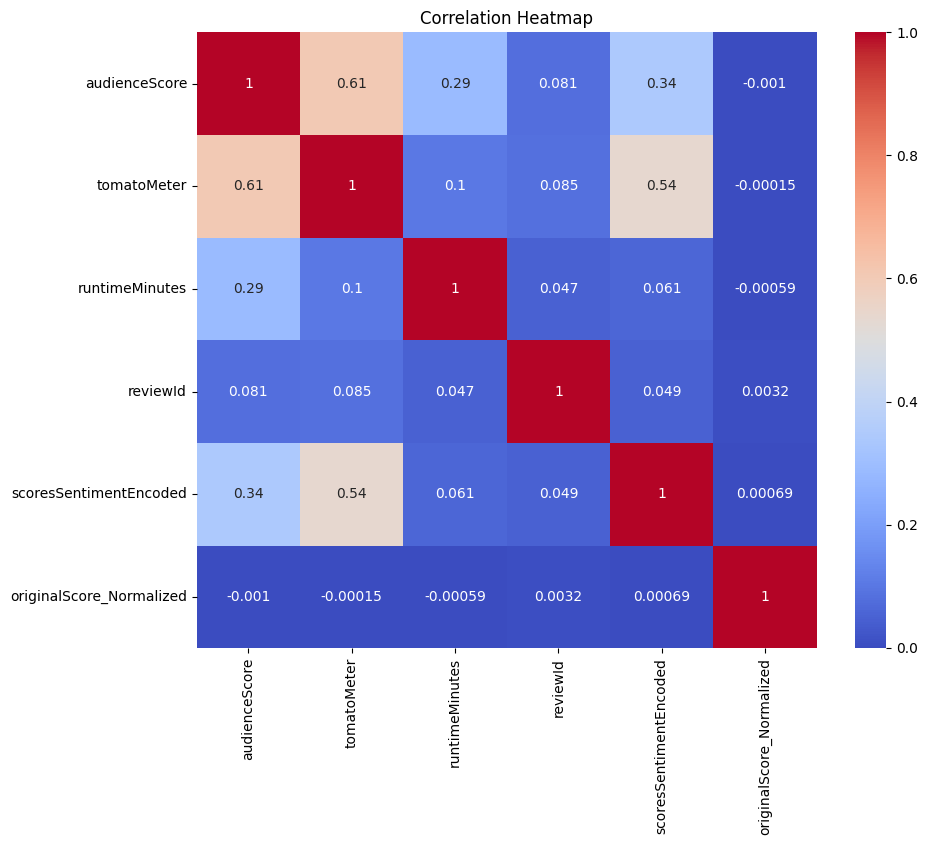

In [42]:
##correlation heat map
col=data.select_dtypes(include=['int64','float64'])
cn=col.corr()
plt.figure(figsize=(10,8))
sns.heatmap(cn,annot=True,cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.savefig('../visualizations/correlation_heatmap.png')
plt.show()

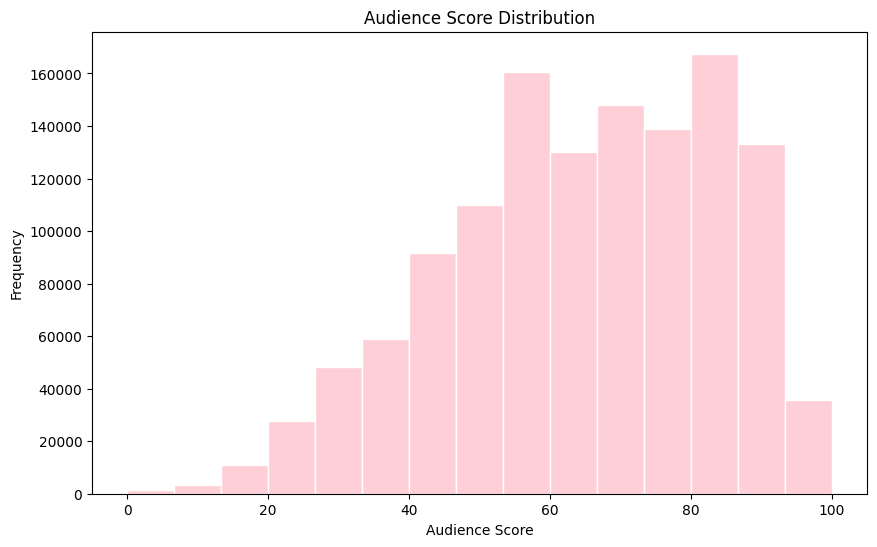

In [43]:
#Audience Score distribution
plt.figure(figsize=(10,6))
sns.histplot(data['audienceScore'],bins=15,color='pink',edgecolor='white')
plt.title('Audience Score Distribution')
plt.xlabel('Audience Score')
plt.ylabel('Frequency')
plt.savefig('../visualizations/audience_score_distribution.png')
plt.show()

In [44]:
data['genre'].value_counts()

genre
Drama                                             188332
Comedy                                             89737
Comedy, Drama                                      76051
Documentary                                        50636
Horror, Mystery & thriller                         41886
                                                   ...  
History, Drama, War, Biography                         1
Documentary, Drama, Sci-fi                             1
Action, Comedy, Fantasy, Horror, Sci-fi                1
Fantasy, Horror, Mystery & thriller, Animation         1
Western, Comedy, Animation                             1
Name: count, Length: 2594, dtype: int64

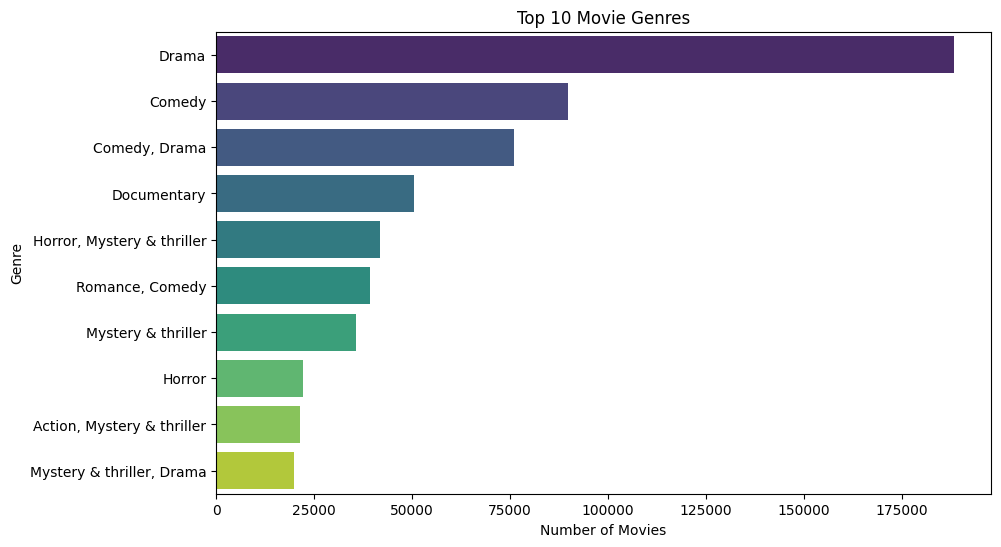

In [45]:
#top 10 genres
t_g=data['genre'].value_counts().head(10)
plt.figure(figsize=(10,6))
sns.barplot(x=t_g.values,y=t_g.index,palette='viridis')

# Add title
plt.title("Top 10 Movie Genres")

# Label x axis
plt.xlabel("Number of Movies")

# Label y axis
plt.ylabel("Genre")
plt.savefig('../visualizations/top_genres.png')
# Show plot
plt.show()

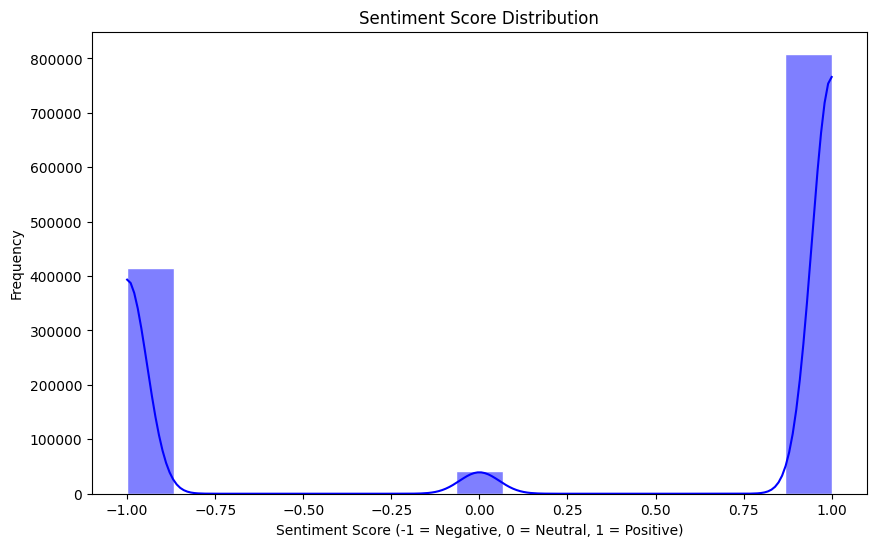

In [46]:
# sentimnet score distrubution
plt.figure(figsize=(10,6))
sns.histplot(data['scoresSentimentEncoded'],bins=15,kde=True,color='blue',edgecolor='white')
plt.title('Sentiment Score Distribution')
plt.xlabel('Sentiment Score (-1 = Negative, 0 = Neutral, 1 = Positive)')
plt.ylabel('Frequency')
plt.savefig('../visualizations/sentiment_score_distribution.png')
plt.show()

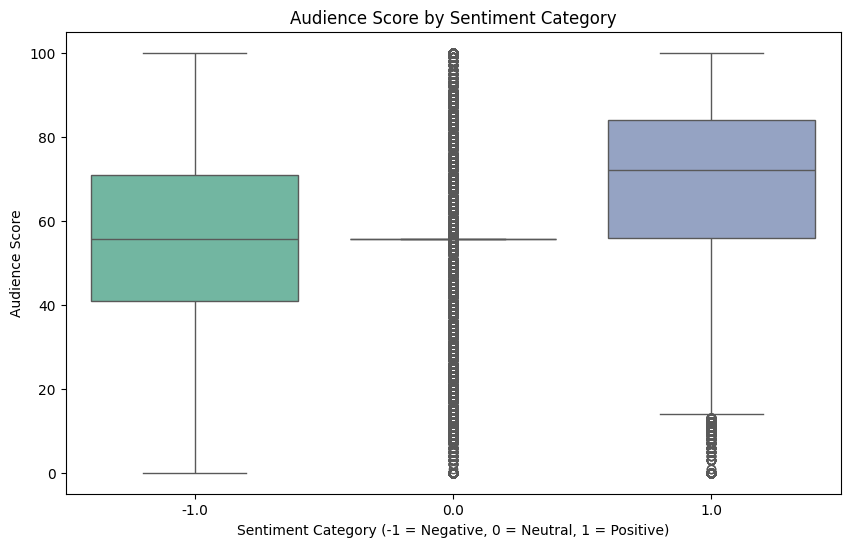

In [47]:
###Box plot
plt.figure(figsize=(10,6))
sns.boxplot(x=data['scoresSentimentEncoded'],y=data['audienceScore'],palette='Set2')
plt.title('Audience Score by Sentiment Category')
plt.savefig('../visualizations/box_plot.png')
plt.xlabel('Sentiment Category (-1 = Negative, 0 = Neutral, 1 = Positive)')
plt.ylabel('Audience Score')
plt.show()

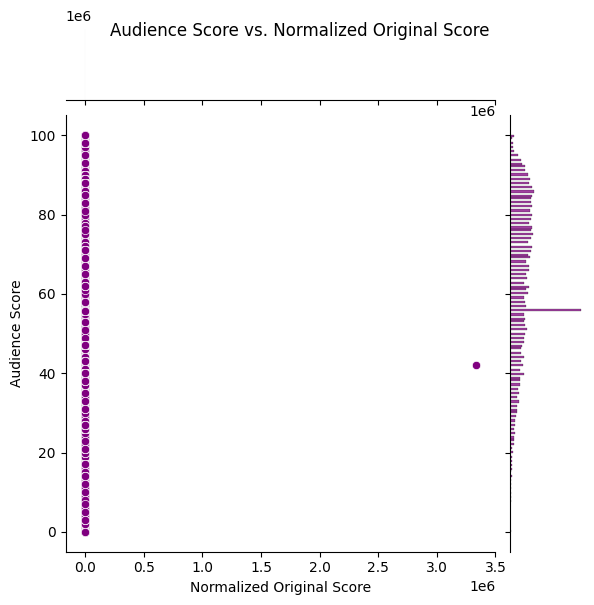

In [48]:
##joint plot different 
sns.jointplot(x='originalScore_Normalized',y='audienceScore',data=data,kind='scatter',color='purple')
plt.suptitle('Audience Score vs. Normalized Original Score')
plt.xlabel('Normalized Original Score')
plt.ylabel('Audience Score')
plt.savefig('../visualizations/scattter_plot.png')
plt.show()

#### Top 10 Directors

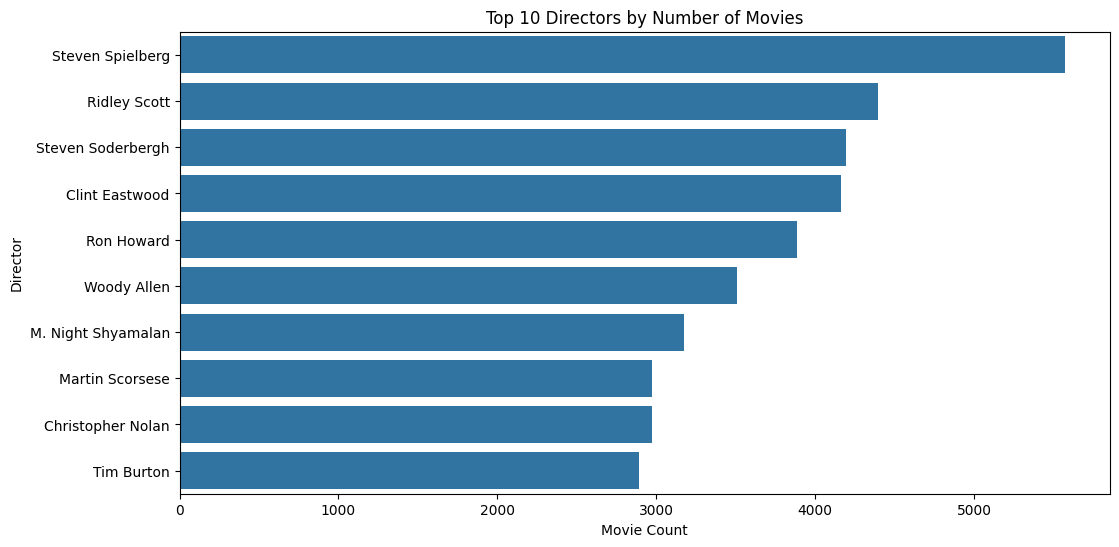

In [49]:
top_directors = data['director'].value_counts().head(10)

plt.figure(figsize=(12,6))
sns.barplot(
    x=top_directors.values,
    y=top_directors.index
)

plt.title("Top 10 Directors by Number of Movies")
plt.xlabel("Movie Count")
plt.ylabel("Director")
plt.savefig('../visualizations/top_directors.png')
plt.show()


#### Top 10 Writers

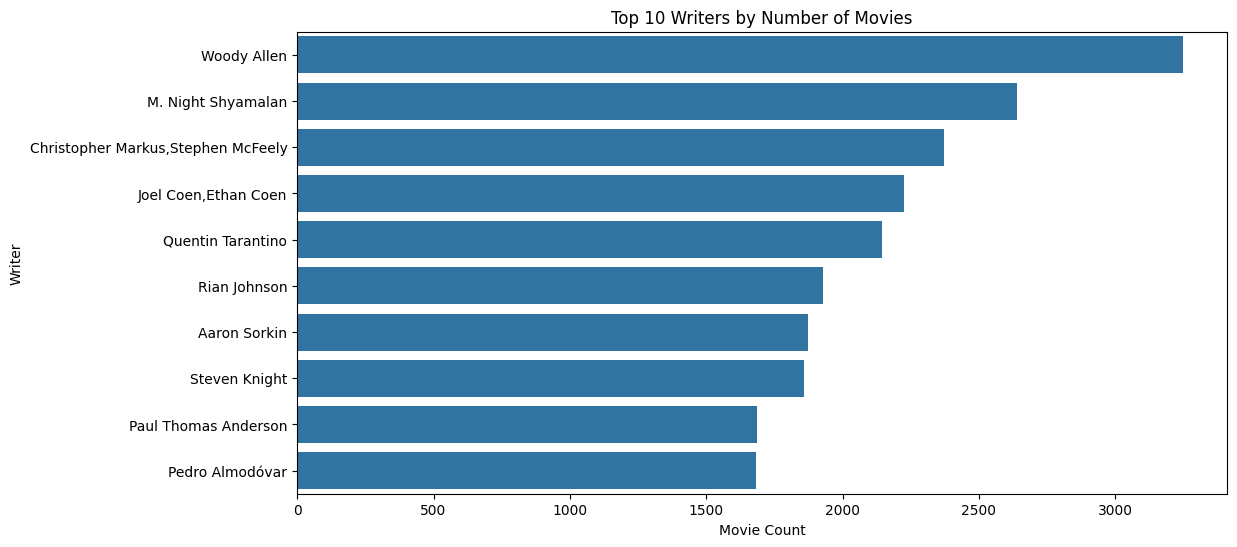

In [50]:
top_writers = data['writer'].value_counts().head(10)

plt.figure(figsize=(12,6))
sns.barplot(
    x=top_writers.values,
    y=top_writers.index
)

plt.title("Top 10 Writers by Number of Movies")
plt.xlabel("Movie Count")
plt.ylabel("Writer")
plt.savefig('../visualizations/top_writers.png')
plt.show()

In [51]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1265703 entries, 0 to 1265702
Data columns (total 19 columns):
 #   Column                    Non-Null Count    Dtype  
---  ------                    --------------    -----  
 0   id                        1265703 non-null  str    
 1   title                     1265703 non-null  str    
 2   audienceScore             1265703 non-null  float64
 3   tomatoMeter               1265703 non-null  float64
 4   rating                    1265703 non-null  str    
 5   ratingContents            830311 non-null   str    
 6   runtimeMinutes            1265703 non-null  float64
 7   genre                     1265703 non-null  str    
 8   originalLanguage          1265703 non-null  str    
 9   director                  1265703 non-null  str    
 10  writer                    1265703 non-null  str    
 11  reviewId                  1224141 non-null  float64
 12  criticName                1224141 non-null  str    
 13  originalScore             847659 non-n

#### Top Languages

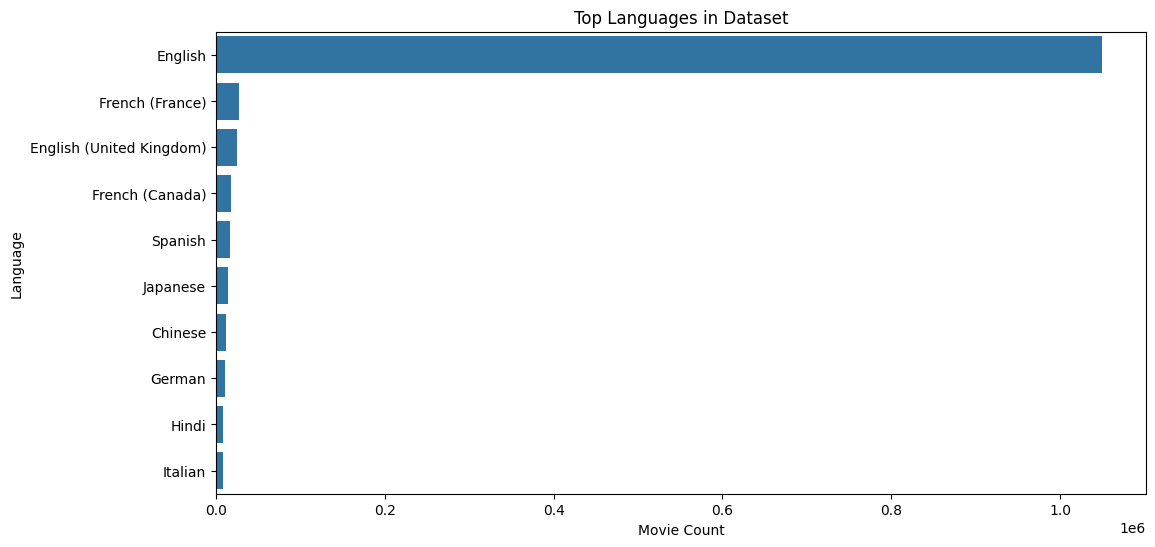

In [52]:
top_languages = data['originalLanguage'].value_counts().head(10)

plt.figure(figsize=(12,6))
sns.barplot(
    x=top_languages.values,
    y=top_languages.index
)

plt.title("Top Languages in Dataset")
plt.xlabel("Movie Count")
plt.ylabel("Language")
plt.savefig('../visualizations/top_languages.png')
plt.show()


#### Runtime Distribution

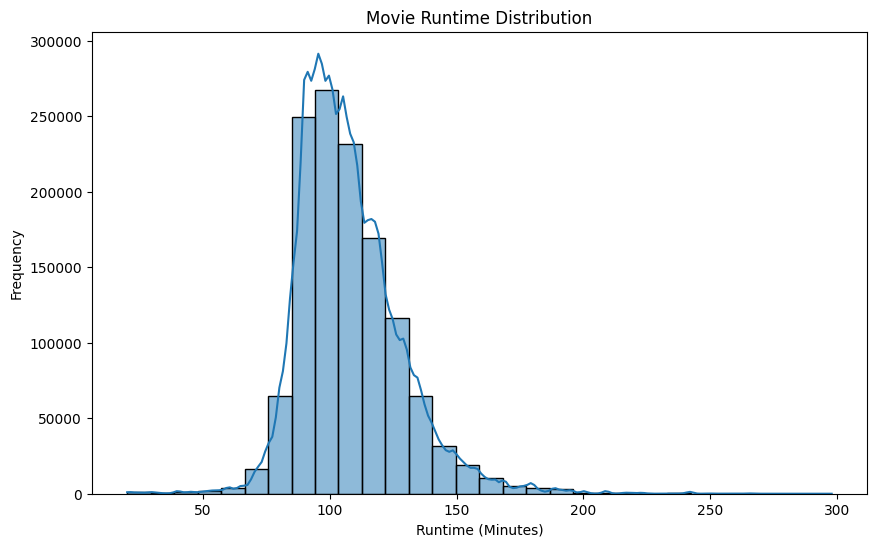

In [53]:
plt.figure(figsize=(10,6))

sns.histplot(
    data['runtimeMinutes'],
    bins=30,
    kde=True
)

plt.title("Movie Runtime Distribution")
plt.xlabel("Runtime (Minutes)")
plt.ylabel("Frequency")
plt.savefig('../visualizations/runtime_distribution.png')
plt.show()

#### Runtime vs Audience Score

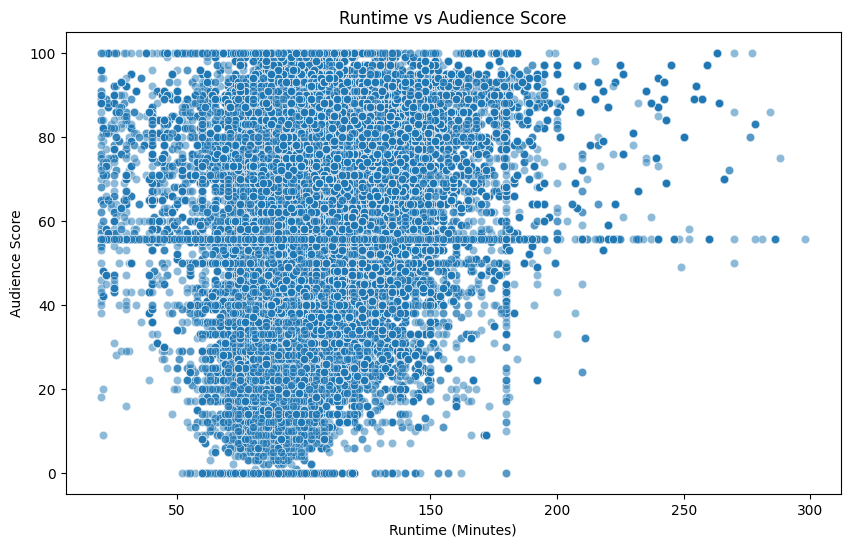

In [54]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    x='runtimeMinutes',
    y='audienceScore',
    data=data,
    alpha=0.5
)

plt.title("Runtime vs Audience Score")
plt.xlabel("Runtime (Minutes)")
plt.ylabel("Audience Score")
plt.savefig('../visualizations/runtime_vs_audience.png')
plt.show()

#### Runtime VS Tomatometer

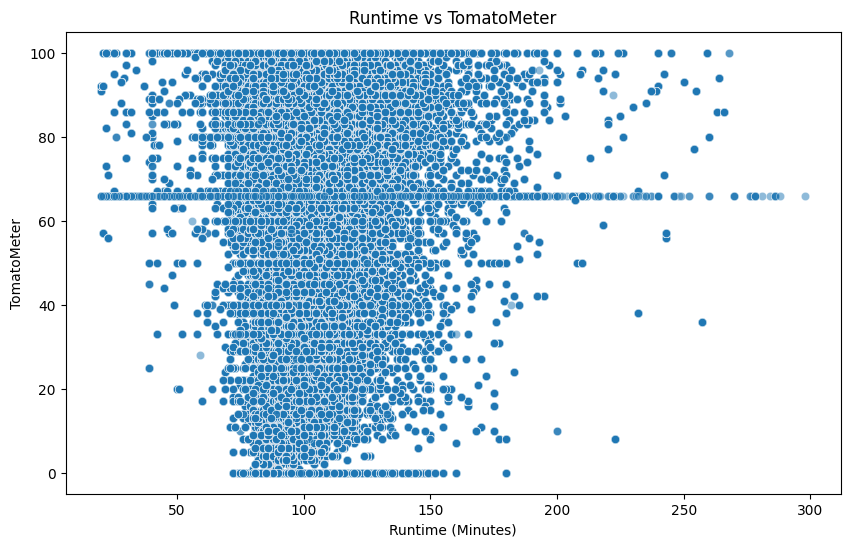

In [55]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    x='runtimeMinutes',
    y='tomatoMeter',
    data=data,
    alpha=0.5
)

plt.title("Runtime vs TomatoMeter")
plt.xlabel("Runtime (Minutes)")
plt.ylabel("TomatoMeter")
plt.savefig('../visualizations/runtime_vs_tomatometer.png')
plt.show()

#### Audience Score categories

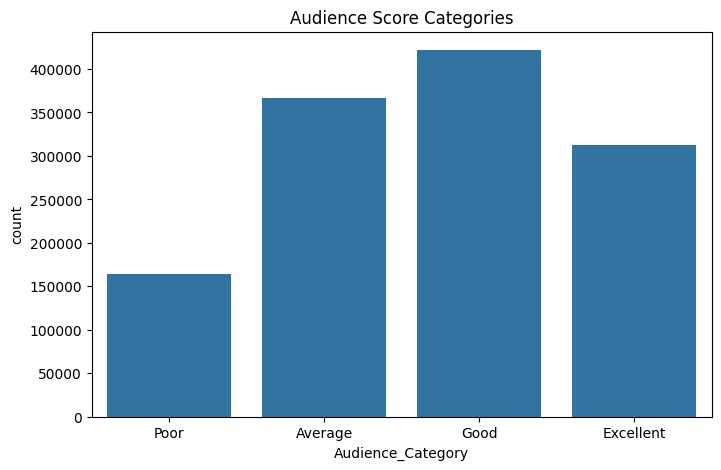

In [56]:
data['Audience_Category'] = pd.cut(
    data['audienceScore'],
    bins=[0,40,60,80,100],
    labels=['Poor','Average','Good','Excellent']
)

plt.figure(figsize=(8,5))

sns.countplot(
    x='Audience_Category',
    data=data
)

plt.title("Audience Score Categories")
plt.savefig('../visualizations/audience_categories.png')
plt.show()


#### Critic score category

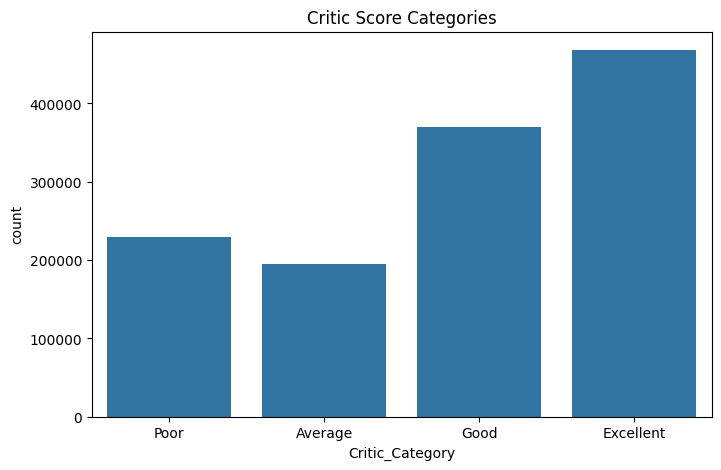

In [57]:
data['Critic_Category'] = pd.cut(#pd.cut() is used to 
    #convert a continuous numerical column into categories (bins).
    data['tomatoMeter'],
    bins=[0,40,60,80,100],
    labels=['Poor','Average','Good','Excellent']
)

plt.figure(figsize=(8,5))

sns.countplot(
    x='Critic_Category',
    data=data
)

plt.title("Critic Score Categories")
plt.savefig('../visualizations/critic_categories.png')
plt.show()

#### Audience vs critic score

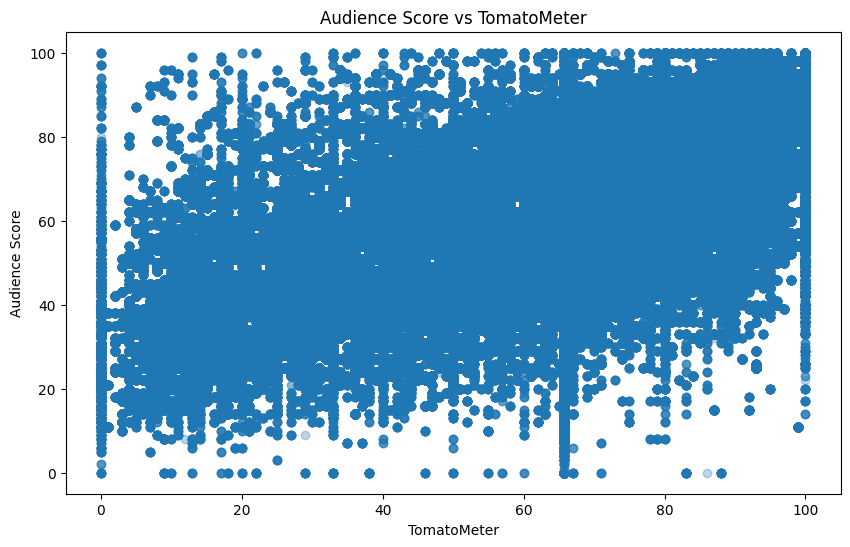

In [58]:
plt.figure(figsize=(10,6))

sns.regplot(
    x='tomatoMeter',
    y='audienceScore',
    data=data,
    scatter_kws={'alpha':0.3}
)

plt.title("Audience Score vs TomatoMeter")
plt.xlabel("TomatoMeter")
plt.ylabel("Audience Score")
plt.savefig('../visualizations/audience_vs_critic.png')

plt.show()


#### Business Insight Summary

In [59]:
print("\nBUSINESS INSIGHT SUMMARY")
print("="*70)

print(
    f"Average Audience Score : {data['audienceScore'].mean():.2f}"
)

print(
    f"Average TomatoMeter : {data['tomatoMeter'].mean():.2f}"
)

print(
    f"Average Runtime : {data['runtimeMinutes'].mean():.2f} minutes"
)

print("\nTOP 5 GENRES")
print(data['genre'].value_counts().head())

print("\nTOP 5 LANGUAGES")
print(data['originalLanguage'].value_counts().head())

print("\nTOP 5 DIRECTORS")
print(data['director'].value_counts().head())

print("\nTOP 5 WRITERS")
print(data['writer'].value_counts().head())



BUSINESS INSIGHT SUMMARY
Average Audience Score : 64.32
Average TomatoMeter : 66.15
Average Runtime : 107.54 minutes

TOP 5 GENRES
genre
Drama                         188332
Comedy                         89737
Comedy, Drama                  76051
Documentary                    50636
Horror, Mystery & thriller     41886
Name: count, dtype: int64

TOP 5 LANGUAGES
originalLanguage
English                     1049145
French (France)               27342
English (United Kingdom)      25382
French (Canada)               17492
Spanish                       16187
Name: count, dtype: int64

TOP 5 DIRECTORS
director
Steven Spielberg     5573
Ridley Scott         4395
Steven Soderbergh    4192
Clint Eastwood       4164
Ron Howard           3884
Name: count, dtype: int64

TOP 5 WRITERS
writer
Woody Allen                           3248
M. Night Shyamalan                    2639
Christopher Markus,Stephen McFeely    2372
Joel Coen,Ethan Coen                  2224
Quentin Tarantino                  

##### Outlier Detection and Treatment

Outliers are extreme values that lie far away from the majority of observations. These values can negatively affect statistical analysis and machine learning model performance.

---

#### Why Important?

Outlier treatment helps to:

- Improve data quality
- Reduce the effect of abnormal values
- Prevent biased analysis
- Improve recommendation accuracy
- Enhance model robustness

---

#### Numerical Features Used

| Feature |
|----------|
| `audienceScore` |
| `tomatoMeter` |
| `runtimeMinutes` |

---

#### Outlier Detection Method

Boxplots are used to visualize outliers in numerical features.

The Interquartile Range (IQR) method is used to calculate the lower and upper bounds.

##### Formula

- **IQR = Q3 − Q1**
- **Lower Bound = Q1 − 1.5 × IQR**
- **Upper Bound = Q3 + 1.5 × IQR**

Values outside these bounds are considered outliers.

---

#### Outlier Treatment Method

Instead of removing outliers, extreme values are capped using the lower and upper bounds obtained from the IQR method.

Capping preserves the dataset while minimizing the influence of abnormal values.

---

#### Visualization

For each numerical feature:

1. A boxplot is generated before treatment to detect outliers.
2. Outliers are capped using the IQR method.
3. A second boxplot is generated after treatment to verify the reduction of outliers.

All visualizations are saved in the `../visualizations/` directory.

---

#### Observation

Boxplots revealed the presence of extreme values in `audienceScore`, `tomatoMeter`, and `runtimeMinutes`. Outliers were treated using the IQR capping technique, which reduced the influence of abnormal values while preserving the overall distribution of the data. This preprocessing step improves the reliability and robustness of the movie recommendation system.

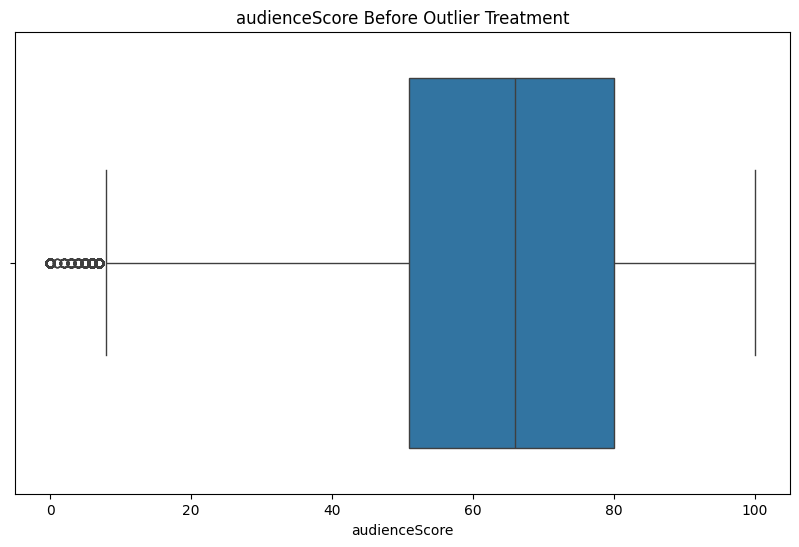

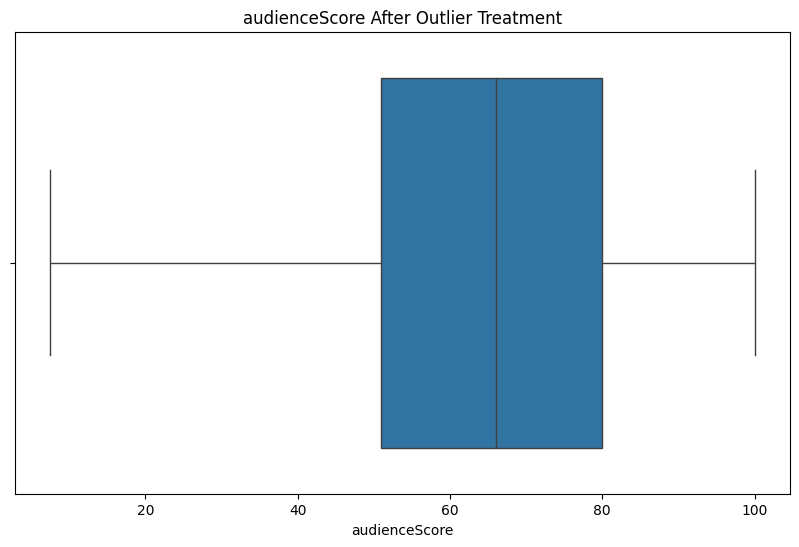

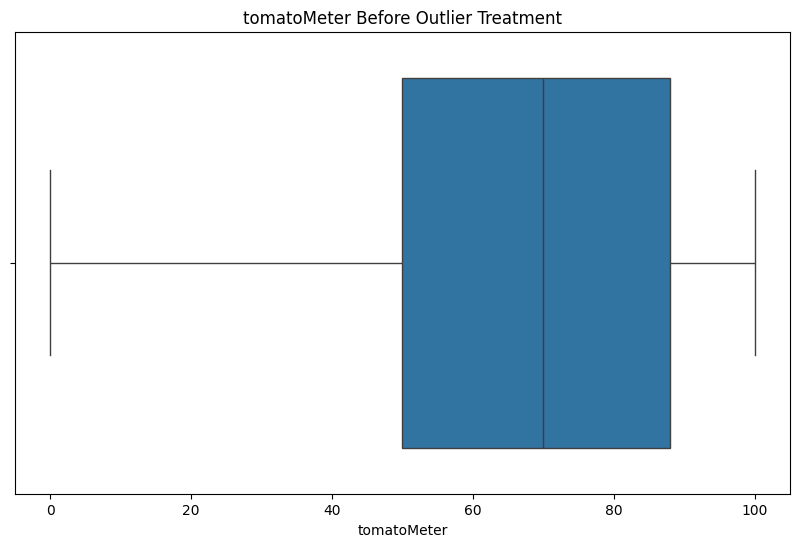

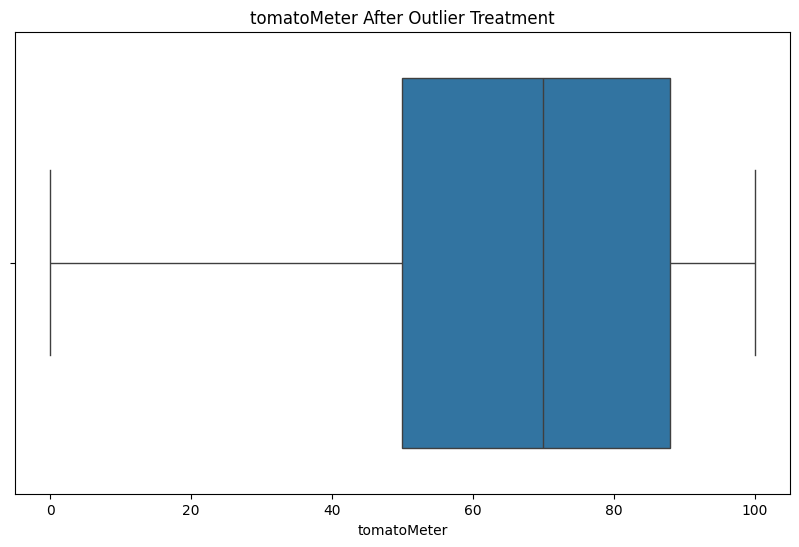

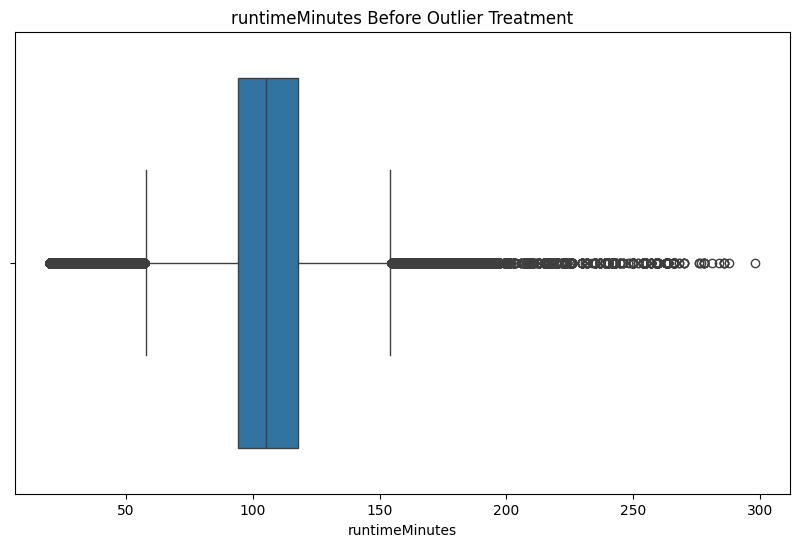

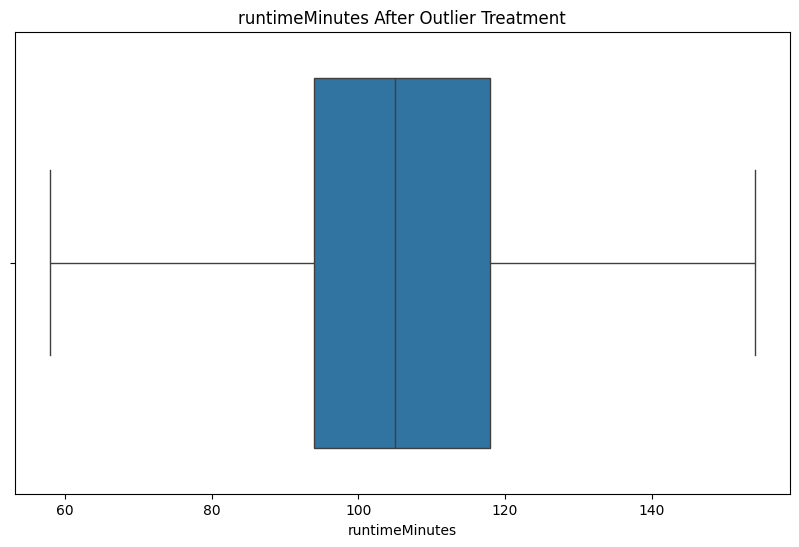

In [60]:
numerical_cols = ['audienceScore', 'tomatoMeter', 'runtimeMinutes']

for col in numerical_cols:

    # Boxplot before treatment
    plt.figure(figsize=(10,6))
    sns.boxplot(x=data[col])
    plt.title(f'{col} Before Outlier Treatment')
    plt.savefig(f'../visualizations/{col}_before_outlier.png')
    plt.show()

    # IQR method
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Cap outliers
    data[col] = data[col].clip(lower=lower_bound,
                               upper=upper_bound)

    # Boxplot after treatment
    plt.figure(figsize=(10,6))
    sns.boxplot(x=data[col])
    plt.title(f'{col} After Outlier Treatment')
    plt.savefig(f'../visualizations/{col}_after_outlier.png')
    plt.show()

In [61]:
import gc
gc.collect()
import psutil
print(psutil.virtual_memory())
print(psutil.virtual_memory().percent)

svmem(total=17179869184, available=7040598016, percent=59.0, used=8402911232, free=129794048, active=6625607680, inactive=6907920384, wired=1777303552)
59.0


##### Top Critics

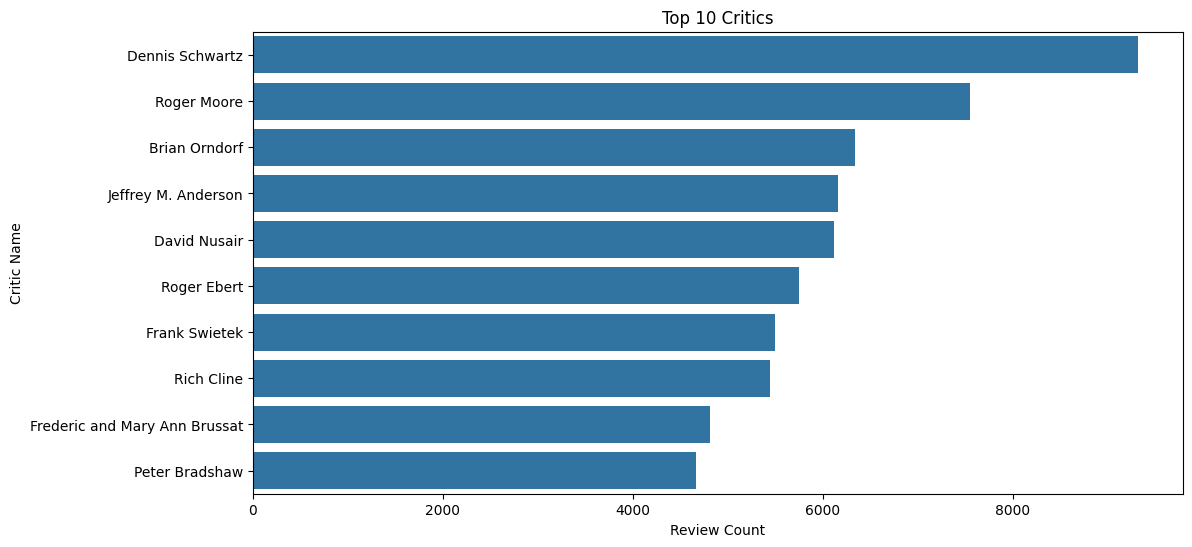

In [62]:
top_critics = data['criticName'].value_counts().head(10)

plt.figure(figsize=(12,6))

sns.barplot(
    x=top_critics.values,
    y=top_critics.index
)

plt.title("Top 10 Critics")
plt.xlabel("Review Count")
plt.ylabel("Critic Name")

plt.savefig('../visualizations/top_critics.png')

plt.show()

##### Top Publications

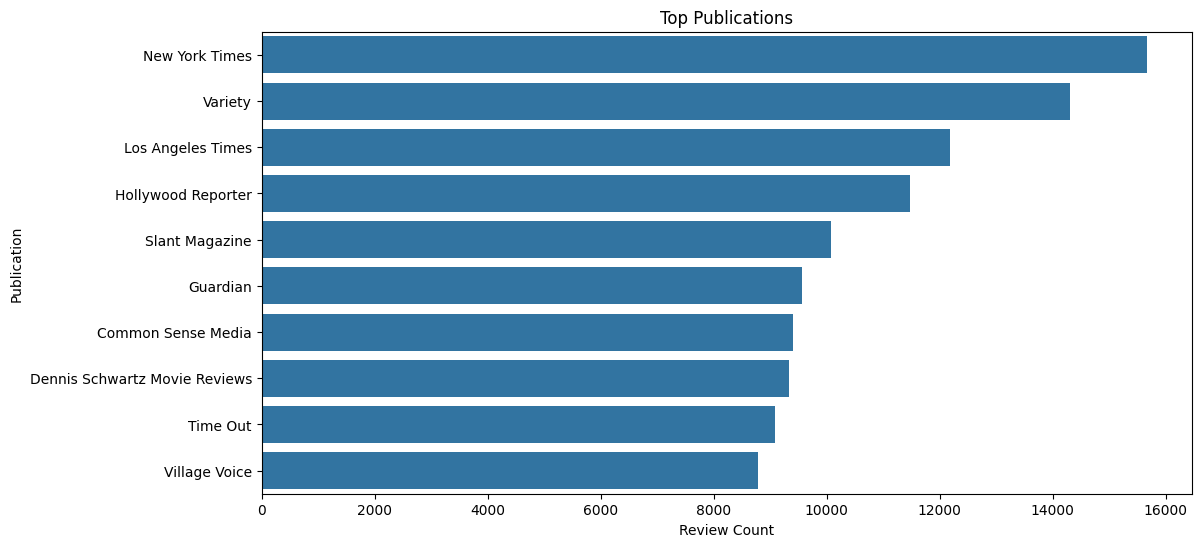

In [63]:
top_publications = data['publicatioName'].value_counts().head(10)

plt.figure(figsize=(12,6))

sns.barplot(
    x=top_publications.values,
    y=top_publications.index
)

plt.title("Top Publications")
plt.xlabel("Review Count")
plt.ylabel("Publication")

plt.savefig('../visualizations/top_publications.png')

plt.show()

##### TomatoMeter Distribution

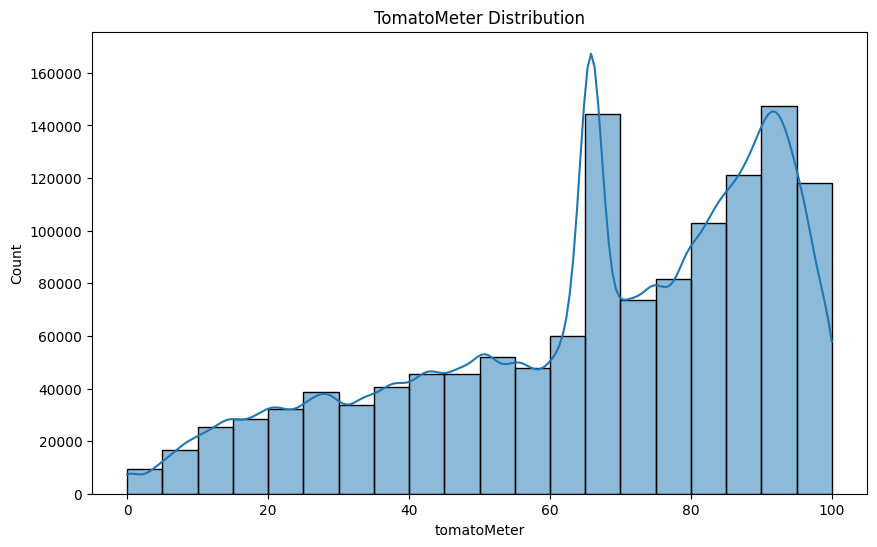

In [64]:
plt.figure(figsize=(10,6))

sns.histplot(
    data['tomatoMeter'],
    bins=20,
    kde=True
)

plt.title("TomatoMeter Distribution")

plt.savefig('../visualizations/tomatometer_distribution.png')

plt.show()

##### Original Score Distribution

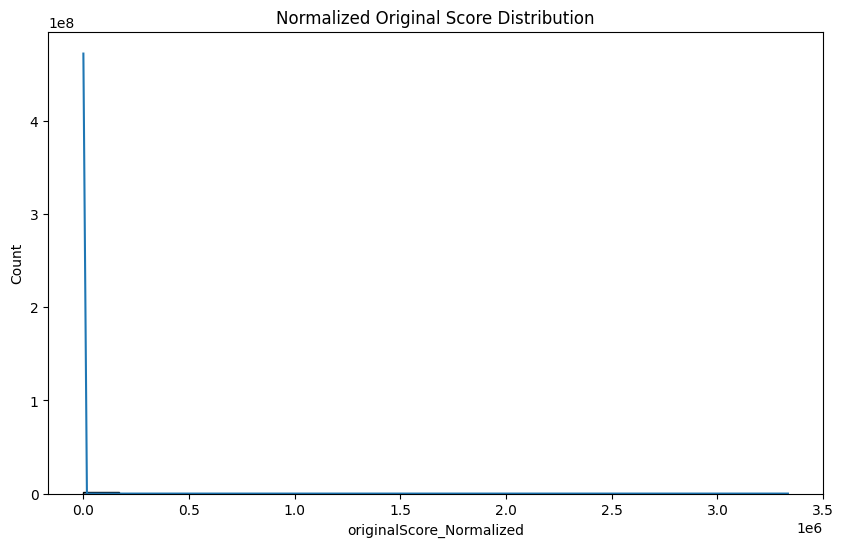

In [65]:
plt.figure(figsize=(10,6))

sns.histplot(
    data['originalScore_Normalized'],
    bins=20,
    kde=True
)

plt.title("Normalized Original Score Distribution")

plt.savefig('../visualizations/original_score_distribution.png')

plt.show()

##### Genre-wise Average Audience Score

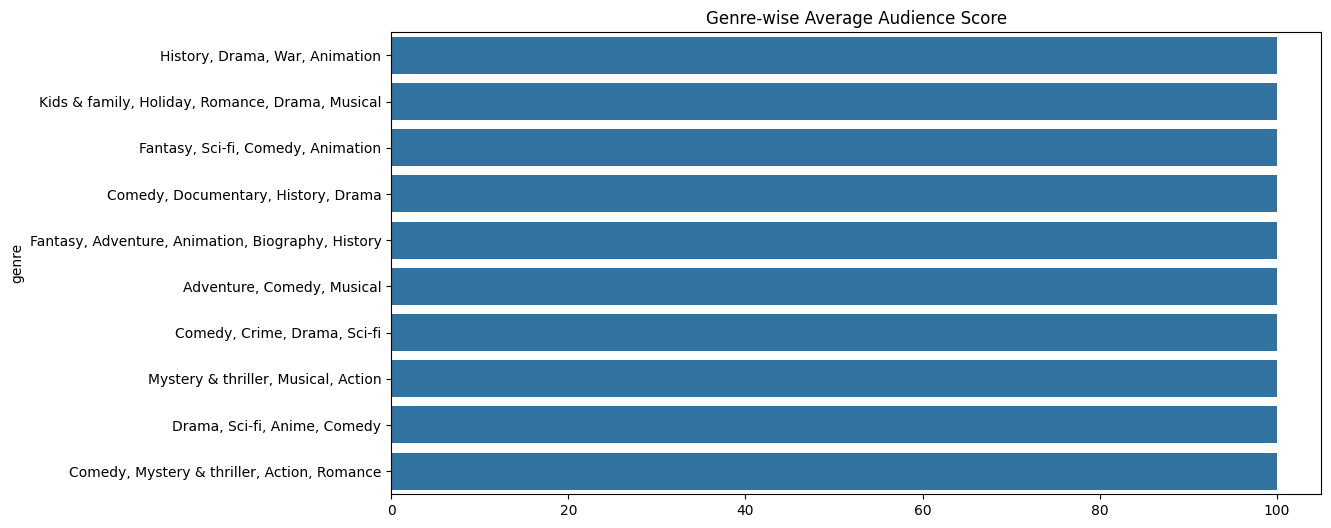

In [66]:
genre_score = data.groupby(
    'genre'
)['audienceScore'].mean().sort_values(
    ascending=False
).head(10)

plt.figure(figsize=(12,6))

sns.barplot(
    x=genre_score.values,
    y=genre_score.index
)

plt.title("Genre-wise Average Audience Score")

plt.savefig('../visualizations/genre_average_score.png')

plt.show()

### Natural Language Processing Setup

#### Purpose
Create NLP tools required for:
- Text preprocessing
- Text cleaning
- Tokenization
- Lemmatization
- Stopword removal

These NLP tools help prepare review text before machine learning processing.

---

#### Why Important?
Raw review text contains:
- Noise
- Unnecessary words
- Different word forms
- Special symbols

NLP setup helps clean and standardize the text.

---

### Stopwords

#### Purpose
Remove common words such as:
- the
- is
- are
- was
- and

---

#### Why Important?
These words:
- Do not improve recommendation quality
- Increase unnecessary text size
- Reduce NLP efficiency

Removing stopwords improves:
- Text quality
- Similarity matching
- Processing speed

---

#### Example

| Original Sentence | After Stopword Removal |
|---|---|
| "The movie is very amazing" | "movie amazing" |

---

### Lemmatization

#### Purpose
Convert words into their root/base form.

---

#### Why Important?
Different forms of the same word should be treated as one word.

This improves:
- Text consistency
- NLP accuracy
- Similarity calculation

---

#### Example

| Original Word | Root Word |
|---|---|
| running | run |
| movies | movie |
| watching | watch |

---

### NLP Libraries Used

| Library | Purpose |
|---|---|
| `nltk` | Natural Language Processing |
| `stopwords` | Remove common words |
| `WordNetLemmatizer` | Convert words into root form |

---

### Small Output

```text
Object created successfully!
```

---

### Benefits of NLP Setup

- Cleaner text data
- Better recommendation accuracy
- Improved text consistency
- Faster NLP processing
- Better similarity matching

---

In [67]:
stop_word=set(stopwords.words('english'))
lemma=WordNetLemmatizer()
print('Object created successfully!')

Object created successfully!


In [68]:
## Text- -preprocessing
def process_text(text):
    #lower case
    text=str(text).lower()
    #remove special char
    text=re.sub(r'[^a-zA-Z0-9 ]', '', text)
    #split
    tokens=word_tokenize(text)
    #remove stopwords
    tokens=[word for word in tokens if word not in stop_word]
    #lemmatization
    tokens=[lemma.lemmatize(word) for word in tokens]
    #rejoin
    text=" ".join(tokens)
    return text
print("Text preprocessing completed successfully!")


Text preprocessing completed successfully!


In [69]:
import gc
gc.collect()

162801

In [70]:
import psutil
print(f"{psutil.virtual_memory().available/1e9:.2f} GB available")
print(f"{psutil.virtual_memory().percent}%")

6.96 GB available
59.5%


### Text Cleaning and Preprocessing

#### Purpose
Clean review text before NLP processing.

Raw review text contains:
- Special characters
- Extra spaces
- Stopwords
- Noise
- Different word formats

These reduce NLP quality and recommendation accuracy.

---

#### Why Important?
Text preprocessing improves:
- NLP quality
- Recommendation accuracy
- Similarity matching
- Text consistency

---

### Text Preprocessing Steps

| Step | Purpose |
|---|---|
| Lowercase conversion | Standardize text |
| Remove special characters | Remove unnecessary symbols |
| Tokenization | Split sentence into words |
| Stopword removal | Remove common unnecessary words |
| Lemmatization | Convert words into root form |
| Rejoin words | Create cleaned sentence |

---

### Lowercase Conversion

#### Purpose
Convert all text into lowercase.

---

#### Why Important?
Treats:
- `Movie`
- `movie`
- `MOVIE`

as the same word.

---

#### Example

| Before | After |
|---|---|
| AMAZING Movie | amazing movie |

---

### Remove Special Characters

#### Purpose
Remove:
- Symbols
- Punctuation
- Special characters

---

#### Why Important?
Special symbols do not improve recommendation quality.

---

#### Example

| Before | After |
|---|---|
| Amazing!!! | Amazing |

---

### Tokenization

#### Purpose
Split sentence into individual words.

---

#### Why Important?
Machine learning processes text word-by-word.

---

#### Example

| Sentence | Tokens |
|---|---|
| movie amazing action | movie, amazing, action |

---

### Stopword Removal

#### Purpose
Remove common words such as:
- the
- is
- are

---

#### Why Important?
These words:
- Add noise
- Do not improve similarity

---

#### Example

| Before | After |
|---|---|
| the movie is amazing | movie amazing |

---

### Lemmatization

#### Purpose
Convert words into root form.

---

#### Why Important?
Different forms of the same word become standardized.

---

#### Example

| Original Word | Root Word |
|---|---|
| running | run |
| movies | movie |
| watching | watch |

---

### Important Columns Preprocessed

| Column |
|---|
| Genre |
| Director |
| Writer |
| Rating Contents |
| Critic Name |
| Publication Name |
| Review Text |

---

### Small Output

```text
Text preprocessing completed successfully!
```

---

### Benefits of Text Preprocessing

- Cleaner text data
- Better NLP quality
- Improved recommendation accuracy
- Better similarity matching
- Reduced noise in dataset

---

In [71]:
### Apply text preprocessing
col_imp=[
    'genre',
    'director',
    'writer',
    'ratingContents',
    'criticName',
    'publicatioName',
    'reviewText'
]
#fill null befor operation
for col in col_imp:
    if col in data.columns:
        data[col]=data[col].fillna('')
for col in col_imp:
    if col in data.columns:
        data[col]=data[col].apply(process_text)
print("Text preprocessing completed successfully!")

Text preprocessing completed successfully!


In [72]:
import gc
gc.collect()

35

In [73]:
import psutil
print(psutil.virtual_memory())
print(psutil.virtual_memory().percent)

svmem(total=17179869184, available=6796902400, percent=60.4, used=8585625600, free=277086208, active=6542934016, inactive=6399197184, wired=2042691584)
60.4


In [74]:
#Sentiment analysis using TextBlob
def get_sent(text):
# calculate sentiment poplarity
    analysis=TextBlob(str(text))
    return analysis.sentiment.polarity
#apply sementent function 
data['score_Sentiment']=data['reviewText'].apply(get_sent)
#display
print(data[['reviewText','score_Sentiment']].head())
print("Sentiment analysis completed successfully!")

                                          reviewText  score_Sentiment
0                                                            0.000000
1                                                            0.000000
2  though let routine love triangle narrative lov...         0.475000
3  perfect love lie worthy discovery time culture...         0.421429
4                                                            0.000000
Sentiment analysis completed successfully!


### Feature Engineering

#### Purpose

Feature engineering combines multiple important features into a single feature to improve recommendation quality.

---

#### Features Combined

| Feature |
|----------|
| Title |
| Genre |
| Director |
| Writer |
| Rating Contents |
| Critic Name |
| Publication Name |
| Review Text |

---

#### Why Important?

Combining multiple features helps:

- Improve similarity calculation.
- Increase recommendation accuracy.
- Capture more movie characteristics.
- Build better text representations.

---

#### Output

A new feature called `combine_features` is created and used for TF-IDF vectorization.

---

In [75]:
#Feature Engineering
data['combine_features']=(
    data['title']+' '+
    data['genre']+' '+
    data['director']+' '+
    data['writer']+' '+
    data['ratingContents']+' '+
    data['criticName']+' '+
    data['publicatioName']+' '+
    data['reviewText']
)
print(data[['combine_features']].head())
print("Feature engineering completed successfully!")

                                    combine_features
0  Space Zombie Bingo! comedy horror scifi george...
1  The Green Grass drama tiffany edward tiffany e...
2  Love, Lies drama park heungsikheungsik park ha...
3  Love, Lies drama park heungsikheungsik park ha...
4  Sore Losers action mystery thriller john micha...
Feature engineering completed successfully!


In [76]:
import gc
gc.collect()

289385

In [77]:
data['combine_features'][1]

'The Green Grass drama tiffany edward tiffany edward    '

### Text Vectorization using TF-IDF

#### Purpose
Convert text into numerical vectors.

---

#### Why Important?
Machine learning models cannot understand raw text directly.

---

#### Parameters Used

| Parameter | Purpose |
|---|---|
| stop_words='english' | Remove stopwords |
| max_features=30000 | Limit vocabulary size |
| ngram_range=(1,2) | Use unigram and bigram |

---

#### Small Output

```text
(50000,30000)
```

---

### Cosine Similarity

#### Purpose

Cosine similarity measures the similarity between movies based on their TF-IDF vectors.

---

#### Why Important?

It helps identify movies with similar:

- Genre
- Director
- Writer
- Reviews
- Overall content

---

#### Similarity Range

| Value | Meaning |
|---------|---------|
| 1 | Completely Similar |
| 0 | No Similarity |

---

Higher similarity values indicate better recommendations.

---

In [78]:
##TF-IDF Vectorization
tfidf=TfidfVectorizer(stop_words='english',max_features=30000,ngram_range=(1,2))
#fit and transform
tfidf_matrix=tfidf.fit_transform(data['combine_features'])
print(tfidf_matrix.shape)
print("TF-IDF vectorization completed successfully!")


(1265703, 30000)
TF-IDF vectorization completed successfully!


In [79]:
import gc
gc.collect()

2

### Content-Based Recommendation Engine

#### Purpose
Recommend movies similar to selected movie.

---

#### Similarity Technique Used

| Technique | Purpose |
|---|---|
| Cosine Similarity | Compare movie vectors |

---

#### Recommendation Process

| Step |
|---|
| Find selected movie |
| Convert into vectors |
| Calculate similarity |
| Display recommendations |

---

#### Small Output

```text
🎬 Top Recommendations Generated
```

---

In [80]:
def recommend_movies(movie,top_n=25):

    # convert movie name to lowercase
    movie = movie.lower()

    # find matching movie
    m_movie = data[
        data['title'].str.lower().str.contains(
            movie,
            na=False
        )
    ]

    # movie not found
    if m_movie.empty:
        print(f"Sorry, no movies found matching '{movie}'.")
        return

    # get movie index
    m_index = m_movie.index[0]

    # get movie title
    m_title = data.iloc[m_index]['title']

    # calculate similarity
    similarity_score = linear_kernel(
        tfidf_matrix[m_index:m_index+1],
        tfidf_matrix
    ).flatten()

    # sort similarity scores
    similar_movie = similarity_score.argsort()[::-1]

    # print heading
    print(f"\n🎬 Top {top_n} Recommendations for '{m_title}'")
    print("=" * 100)

    # create empty set
    seen_movies = set()

    # recommendation counter
    count = 0

    # loop through movies
    for idx in similar_movie:

        # get title
        title = data.iloc[idx]['title']

        # skip repeated movies
        if title in seen_movies:
            continue

        # add title to set
        seen_movies.add(title)

        # increase counter
        count += 1

        # print recommendation number
        print(f"\nRecommendation #{count}")

        # print movie details
        print("Movie       :", title)

        print("Genre       :", data.iloc[idx]['genre'])

        print("Director    :", data.iloc[idx]['director'])

        print("Audience    :", data.iloc[idx]['audienceScore'])

        print("TomatoMeter :", data.iloc[idx]['tomatoMeter'])

        print(
            "Similarity  :",
            round(similarity_score[idx], 4)
        )

        print("-" * 100)

        # stop after top_n
        if count == top_n:
            break

In [81]:
recommend_movies("How to Train Your Dragon")


🎬 Top 25 Recommendations for 'How to Train Your Dragon'

Recommendation #1
Movie       : How to Train Your Dragon
Genre       : kid family fantasy adventure comedy animation
Director    : christopher sandersdean deblois
Audience    : 100.0
TomatoMeter : 65.77034566224873
Similarity  : 1.0
----------------------------------------------------------------------------------------------------

Recommendation #2
Movie       : How to Train Your Dragon 2
Genre       : kid family fantasy adventure comedy animation
Director    : dean debloistom owen
Audience    : 90.0
TomatoMeter : 92.0
Similarity  : 0.4016
----------------------------------------------------------------------------------------------------

Recommendation #3
Movie       : How to Train Your Dragon: The Hidden World
Genre       : kid family fantasy adventure comedy animation
Director    : dean deblois
Audience    : 55.67496723460026
TomatoMeter : 65.77034566224873
Similarity  : 0.3579
---------------------------------------------

In [82]:
recommend_movies("pace Zombie Bingo")


🎬 Top 25 Recommendations for 'Space Zombie Bingo!'

Recommendation #1
Movie       : Space Zombie Bingo!
Genre       : comedy horror scifi
Director    : george ormrod
Audience    : 50.0
TomatoMeter : 65.77034566224873
Similarity  : 1.0
----------------------------------------------------------------------------------------------------

Recommendation #2
Movie       : Skateboard
Genre       : action
Director    : george gage
Audience    : 55.67496723460026
TomatoMeter : 65.77034566224873
Similarity  : 0.5164
----------------------------------------------------------------------------------------------------

Recommendation #3
Movie       : Mannu
Genre       : drama
Director    : kg george
Audience    : 55.67496723460026
TomatoMeter : 65.77034566224873
Similarity  : 0.5066
----------------------------------------------------------------------------------------------------

Recommendation #4
Movie       : Zombie Planet
Genre       : horror
Director    : george bonilla
Audience    : 20.0
T

In [83]:
print(data['title'].head(20))

0     Space Zombie Bingo!
1         The Green Grass
2              Love, Lies
3              Love, Lies
4             Sore Losers
5         Dinosaur Island
6                  Adrift
7                  Adrift
8                  Adrift
9                  Adrift
10                 Adrift
11                 Adrift
12                 Adrift
13                 Adrift
14                 Adrift
15                 Adrift
16                 Adrift
17                 Adrift
18                 Adrift
19                 Adrift
Name: title, dtype: str


### Model Persistence

#### Purpose
Save trained files for future use.

---

#### Files Saved

| File |
|---|
| Clean Dataset |
| TF-IDF Vectorizer |
| TF-IDF Matrix |

---

#### Why Important?
- Faster execution
- Easy deployment
- Reusable model

---

In [84]:
import joblib
joblib.dump(data,'../models/movie_data.pkl')
##tf-idf vectore
joblib.dump(tfidf,'../models/tfidf_vectorizer.pkl')
#matrix
joblib.dump(tfidf_matrix,'../models/tfidf_matrix.pkl')
print("Data and models saved successfully!")

Data and models saved successfully!


In [85]:
data.to_csv('../outputs/cleaned_movies_data.csv', index=False)
print("Cleaned data saved to 'outputs/cleaned_movies_data.csv' successfully!")

Cleaned data saved to 'outputs/cleaned_movies_data.csv' successfully!


In [86]:
import os
os.listdir('../models')

['tfidf_vectorizer.pkl', 'movie_data.pkl', 'tfidf_matrix.pkl']

### Final Recommendation Testing

#### Purpose
Test the recommendation system using movie names.

---

#### Why Important?
Verifies:
- Model working properly
- Recommendation quality
- Similarity accuracy

---

#### Small Output

```text
🎬 Top Recommendations for data 
```

---

In [87]:
##Load joblib files
data_load=joblib.load('../models/movie_data.pkl')
tfidf_load=joblib.load('../models/tfidf_vectorizer.pkl')
tfidf_matrix_load=joblib.load('../models/tfidf_matrix.pkl')
print("Data and models loaded successfully!")

Data and models loaded successfully!


In [88]:
data_load.head()

,id,title,audienceScore,tomatoMeter,rating,ratingContents,runtimeMinutes,genre,originalLanguage,director,...,originalScore,publicatioName,reviewText,scoreSentiment,scoresSentimentEncoded,originalScore_Normalized,Audience_Category,Critic_Category,score_Sentiment,combine_features
0,space-zombie-bingo,Space Zombie Bingo!,50.000000,65.770346,R,,75.0,comedy horror scifi,English,george ormrod,...,NaN,,,NaN,0.0,0.7,Average,Good,0.000000,Space Zombie Bingo! comedy horror scifi george...
1,the_green_grass,The Green Grass,55.674967,65.770346,R,,114.0,drama,English,tiffany edward,...,NaN,,,NaN,0.0,0.7,Average,Good,0.000000,The Green Grass drama tiffany edward tiffany e...
2,love_lies,"Love, Lies",43.000000,65.770346,R,,120.0,drama,Korean,park heungsikheungsik park,...,4/5,easternkickscom,though let routine love triangle narrative lov...,POSITIVE,1.0,0.8,Average,Good,0.475000,"Love, Lies drama park heungsikheungsik park ha..."
3,love_lies,"Love, Lies",43.000000,65.770346,R,,120.0,drama,Korean,park heungsikheungsik park,...,3.5/5,thedivareviewcom,perfect love lie worthy discovery time culture...,POSITIVE,1.0,0.7,Average,Good,0.421429,"Love, Lies drama park heungsikheungsik park ha..."
4,the_sore_losers_1997,Sore Losers,60.000000,65.770346,R,,90.0,action mystery thriller,English,john michael mccarthy,...,NaN,,,NaN,0.0,0.7,Average,Good,0.000000,Sore Losers action mystery thriller john micha...


In [89]:
recommend_movies("Sore Losers")


🎬 Top 25 Recommendations for 'Sore Losers'

Recommendation #1
Movie       : Sore Losers
Genre       : action mystery thriller
Director    : john michael mccarthy
Audience    : 60.0
TomatoMeter : 65.77034566224873
Similarity  : 1.0
----------------------------------------------------------------------------------------------------

Recommendation #2
Movie       : Superstarlet A.D.
Genre       : comedy scifi
Director    : john michael mccarthy
Audience    : 73.0
TomatoMeter : 65.77034566224873
Similarity  : 0.7836
----------------------------------------------------------------------------------------------------

Recommendation #3
Movie       : Finale
Genre       : horror mystery thriller
Director    : john michael elfers
Audience    : 20.0
TomatoMeter : 65.77034566224873
Similarity  : 0.7275
----------------------------------------------------------------------------------------------------

Recommendation #4
Movie       : Hope Again
Genre       : comedy drama
Director    : john micha

In [90]:
recommend_movies("The Green Grass")


🎬 Top 25 Recommendations for 'The Green Grass'

Recommendation #1
Movie       : The Green Grass
Genre       : drama
Director    : tiffany edward
Audience    : 55.67496723460026
TomatoMeter : 65.77034566224873
Similarity  : 1.0
----------------------------------------------------------------------------------------------------

Recommendation #2
Movie       : Welcome Back
Genre       : drama
Director    : tiffany k guillen
Audience    : 55.67496723460026
TomatoMeter : 65.77034566224873
Similarity  : 0.7234
----------------------------------------------------------------------------------------------------

Recommendation #3
Movie       : The Perfect Sacrifice
Genre       : drama
Director    : tiffany littlejohn
Audience    : 55.67496723460026
TomatoMeter : 65.77034566224873
Similarity  : 0.6752
----------------------------------------------------------------------------------------------------

Recommendation #4
Movie       : Collision
Genre       : drama
Director    : tiffany rhodes
A

# Project Overview and Conclusion

## Project Type
🎬 Content-Based Movie Recommendation System

---

## Technologies Used

| Technology | Purpose |
|---|---|
| NLP | Text processing |
| Sentiment Analysis | Review understanding |
| TF-IDF | Text vectorization |
| Cosine Similarity | Movie similarity |

---

## Final Workflow

```text
Dataset Loading
      ↓
Data Cleaning
      ↓
Missing Value Handling
      ↓
Normalization
      ↓
EDA & Visualization
      ↓
Outlier Treatment
      ↓
Text Preprocessing
      ↓
Sentiment Analysis
      ↓
Feature Engineering
      ↓
TF-IDF Vectorization
      ↓
Cosine Similarity
      ↓
Recommendation Engine
      ↓
Model Saving
      ↓
Testing
```

---

## Final Conclusion

This project recommends movies using:
- NLP
- Sentiment Analysis
- TF-IDF
- Cosine Similarity

to provide accurate and personalized movie recommendations.

---